# EDA интерактивной истории The Intercept

**Цель:** изучить структуру истории и размеченные вводы игроков перед разработкой
сопоставления «контекст + свободный ввод + авторские варианты → choice_id или отказ».

Единицы анализа различаются:

- **Карточка** — момент выбора или сюжетный финал.
- **Вариант ответа** — действие внутри карточки. Один исходный вариант может встречаться в нескольких контекстах подистории.
- **Маршрут** — путь после ответа до следующей карточки с условиями и всем текстом между выборами.
- **Контекст входа** — текст, который привёл к карточке после предыдущего выбора.
- **Ввод игрока** — отдельный текст с меткой авторского варианта текущей карточки или `null`.

Сюжет и размеченные вводы анализируются раздельно. Количество примеров каждого действия
описывает состав датасета, а не популярность действий в игровых сессиях.
Условия, счётчики посещений и `once_only` не исполняются. Переход означает структурную возможность,
а не доказанную достижимость при конкретном состоянии игры. Записи ⟨… / …⟩ сохраняют варианты текста.

In [1]:
from pathlib import Path
import sys
import json
import re
import itertools
import csv
import importlib.metadata as package_metadata
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import networkx as nx
from sklearn.feature_extraction.text import TfidfVectorizer
from IPython.display import display, Image, Markdown

ROOT = next((p for p in (Path.cwd(), Path.cwd().parent)
             if (p / 'data' / 'story_cards.json').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Открой notebook из корня проекта или папки notebooks.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from scripts.prepare_story_data import tables, validate

DATA = ROOT / 'data' / 'story_cards.json'
OUT = ROOT / 'eda'
FIGURES = OUT / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
dataset = json.loads(DATA.read_text(encoding='utf-8'))

pd.set_option('display.max_colwidth', 110)
pd.set_option('display.max_rows', 30)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': 'white', 'axes.facecolor': 'white'})
BLUE, ORANGE, GREEN, GREY = '#2874a6', '#bd7537', '#40866b', '#9aa5b1'

def save_plot(fig, name):
    fig.savefig(FIGURES / f'{name}.png', dpi=180, bbox_inches='tight')
    display(Image(filename=str(FIGURES / f'{name}.png')))
    plt.close(fig)

versions = {name: package_metadata.version(name) for name in
            ['pandas', 'numpy', 'matplotlib', 'networkx', 'scikit-learn']}
display(pd.Series(versions, name='Установленная версия').to_frame())


,Установленная версия
pandas,2.3.3
numpy,2.5.0
matplotlib,3.11.0
networkx,3.7
scikit-learn,1.9.0


## 1. Формат JSON и пример карточки

`story` содержит полный текст при единственном контексте входа или общий суффикс при нескольких.
Точный сюжет **от предыдущего выбора** находится в `choice.routes[].story` и в таблице `contexts`.
`previous` ссылается на исходную карточку, ответ и маршрут, которые привели к текущей карточке.

Если ответ имеет одну карточку назначения, указан `target_id`. Если назначений несколько,
`target_id = null` — это не потеря ссылки: назначения и условия перечислены в `routes`.
Финалы имеют `choices = []` и `user_inputs = []`.
В `user_inputs` хранятся `text`, правильный `choice_id`, ссылка `context_id` и объяснение `rationale`.
Последнее нужно для проверки разметки и не является входным признаком модели.

In [2]:
validate(dataset)
by_id = {card['id']: card for card in dataset['cards']}
start_id = dataset['start_card_id']
example = by_id[start_id]
compact_example = {
    'id': example['id'], 'story': example['story'],
    'choices': [{'id': o['id'], 'text': o['text'], 'target_id': o['target_id'],
                 'routes': [{'target_id': r['target_id'], 'conditions': r['conditions']}
                            for r in o['routes']]} for o in example['choices']],
    'user_inputs': example.get('user_inputs', [])[:2],
}
print(json.dumps(compact_example, ensure_ascii=False, indent=2))
print('Начальная карточка:', start_id)
print('Покрытие исходника:', dataset['metadata']['coverage'])


{
  "id": "intercept_001",
  "story": "Меня заставляют ждать.",
  "choices": [
    {
      "id": "choice:78",
      "text": "Барак № 14",
      "target_id": "intercept_002",
      "routes": [
        {
          "target_id": "intercept_002",
          "conditions": []
        }
      ]
    }
  ],
  "user_inputs": [
    {
      "id": "input_001_001",
      "text": "Я жду в четырнадцатом бараке.",
      "choice_id": "choice:78",
      "context_id": "intercept_entry_01",
      "rationale": "Продолжает сцену ожидания в бараке № 14."
    },
    {
      "id": "input_001_002",
      "text": "Продолжим с барака, где меня держат.",
      "choice_id": "choice:78",
      "context_id": "intercept_entry_01",
      "rationale": "Продолжает сцену ожидания в бараке № 14."
    }
  ]
}
Начальная карточка: intercept_001
Покрытие исходника: {'source_story_lines': 644, 'covered_story_lines': 644, 'unique_source_choices': 340, 'cards': 132, 'choice_occurrences': 350, 'routes': 670}


## 2. Нормализованные таблицы и объём данных

Карточки и ответы — разные единицы. При подсчёте частоты формулировок используем уникальные исходные
`choice_id`, чтобы повторные контексты подистории не увеличивали частоты искусственно.
Контексты считаем как с повторениями маршрутов, так и по уникальным парам `(card_id, story)`.
Вводы извлекаются непосредственно из JSON; таблица `user_inputs.csv` проверяется на соответствие ему.

In [3]:
normalised = tables(dataset)
cards_df = pd.DataFrame(normalised['cards'])
choices_df = pd.DataFrame(normalised['choices'])
routes_df = pd.DataFrame(normalised['routes'])
contexts_df = pd.DataFrame(normalised['contexts'])

context_lookup = contexts_df.set_index('context_id').to_dict('index')
input_rows = []
for card in dataset['cards']:
    option_lookup = {o['id']: o for o in card['choices']}
    for item in card.get('user_inputs', []):
        ctx = context_lookup.get(item.get('context_id'))
        option = option_lookup.get(item.get('choice_id'))
        input_rows.append({
            'input_id': item['id'], 'card_id': card['id'],
            'text': item['text'], 'choice_id': item['choice_id'],
            'choice_text': option['text'] if option else None,
            'choice_conditions': json.dumps(option['conditions'] if option else [], ensure_ascii=False),
            'context_id': item.get('context_id'),
            'context_story': ctx['story'] if ctx else card['story'],
            'context_conditions': ctx['conditions'] if ctx else '[]',
            'rationale': item.get('rationale', ''),
            'source_group_id': card['source']['group_id'],
            'candidate_count': len(card['choices']),
            'n_conditioned_candidates': sum(bool(o['conditions']) for o in card['choices']),
            'structurally_reachable': card['reachable_from_start'],
        })
if not input_rows:
    raise ValueError('В JSON нет user_inputs: нужен датасет с размеченным вводом.')
inputs_df = pd.DataFrame(input_rows)
inputs_df['is_match'] = inputs_df.choice_id.notna()
inputs_df['label_type'] = np.where(inputs_df.is_match, 'Есть соответствие', 'Нет соответствия (null)')
inputs_df['has_context'] = inputs_df.context_id.isin(context_lookup) & inputs_df.context_story.str.strip().ne('')
inputs_df['normalized_text'] = inputs_df.text.map(lambda text: re.sub(r'\W+', '', text.casefold()))
inputs_df['n_context_words'] = inputs_df.context_story.map(lambda text: len(re.findall(r'\b\w+\b', text)))

word_pattern = re.compile(r'\b[А-Яа-яЁёA-Za-z0-9]+\b')
for frame, column in [(cards_df, 'story'), (choices_df, 'choice_text'),
                      (routes_df, 'story_after_choice'), (contexts_df, 'story'), (inputs_df, 'text')]:
    frame['n_chars'] = frame[column].fillna('').str.len()
    frame['n_words'] = frame[column].fillna('').map(lambda text: len(word_pattern.findall(text)))
    frame['has_inline_variants'] = frame[column].fillna('').str.contains('⟨', regex=False)
choices_df['has_condition'] = choices_df['conditions'].map(lambda value: bool(json.loads(value)))
routes_df['n_conditions'] = routes_df['conditions'].map(lambda value: len(json.loads(value)))
unique_choices = choices_df.drop_duplicates('choice_id').copy()
unique_contexts = contexts_df.drop_duplicates(['card_id', 'story']).copy()
decisions = cards_df[cards_df.kind.eq('decision')].copy()
endings = cards_df[cards_df.kind.eq('ending')].copy()

metrics = pd.Series({
    'Историй': 1,
    'Карточек': len(cards_df),
    'Карточек с выбором': len(decisions),
    'Сюжетных финалов': len(endings),
    'Вхождений вариантов ответа': len(choices_df),
    'Уникальных исходных вариантов ответа': choices_df.choice_id.nunique(),
    'Маршрутов': len(routes_df),
    'Контекстов, включая начальный': len(contexts_df),
    'Уникальных пар (карточка, текст контекста)': len(unique_contexts),
    'Вводов игроков': len(inputs_df),
    'Вводов с авторским вариантом': int(inputs_df.is_match.sum()),
    'Вводов без соответствия (null)': int((~inputs_df.is_match).sum()),
    'Уникальных формулировок ввода': inputs_df.normalized_text.nunique(),
}, name='Количество')
display(metrics.to_frame())
display(cards_df[['card_id','kind','n_choices','story_mode','n_context_variants','story']].head(5))
display(inputs_df[['input_id','card_id','context_id','text','choice_id','choice_text']].head(8))


,Количество
Историй,1
Карточек,132
Карточек с выбором,128
Сюжетных финалов,4
Вхождений вариантов ответа,350
Уникальных исходных вариантов ответа,340
Маршрутов,670
"Контекстов, включая начальный",671
"Уникальных пар (карточка, текст контекста)",581
Вводов игроков,2134


,card_id,kind,n_choices,story_mode,n_context_variants,story
0,intercept_001,decision,1,single_context,1,Меня заставляют ждать.
1,intercept_002,decision,3,shared_suffix,2,⟨… / Я барабаню пальцами по походному столу. / …⟩
2,intercept_003,decision,3,single_context,1,"⟨Вообще-то я умею / Я умею⟩ решать задачи. Хорошо считаю, быстро разгадываю кроссворды, отлично играю в ша..."
3,intercept_004,decision,3,shared_suffix,4,"Коммандер Харрис возвращается через полчаса. Он быстро закрывает за собой дверь, словно боится, что внутрь..."
4,intercept_005,decision,4,shared_suffix,3,Он принёс чай в двух металлических кружках и ставит их на стол между нами.


,input_id,card_id,context_id,text,choice_id,choice_text
0,input_001_001,intercept_001,intercept_entry_01,Я жду в четырнадцатом бараке.,choice:78,Барак № 14
1,input_001_002,intercept_001,intercept_entry_01,"Продолжим с барака, где меня держат.",choice:78,Барак № 14
2,input_001_003,intercept_001,intercept_entry_01,Остаюсь в бараке номер четырнадцать.,choice:78,Барак № 14
3,input_001_004,intercept_001,intercept_entry_01,"Посмотрю, что происходит в этом бараке.",choice:78,Барак № 14
4,input_001_005,intercept_001,intercept_entry_01,"Ладно, я здесь, в бараке 14, что дальше?",choice:78,Барак № 14
5,input_001_006,intercept_001,intercept_entry_01,Закажу пиццу с доставкой.,None,None
6,input_001_007,intercept_001,intercept_entry_01,Открою портал в другую галактику.,None,None
7,input_001_008,intercept_001,intercept_entry_01,Сколько сейчас стоит биткоин?,None,None


## 3. Качество данных и целостность переходов

Ошибки структуры проверяем отдельно от особенностей сюжета. Пустой **общий** текст карточки
может быть следствием нескольких входящих контекстов. Повтор ответа в одной карточке требует просмотра
условий, но сам по себе не доказывает ошибку: варианты могут быть взаимоисключающими.

In [4]:
card_ids = set(cards_df.card_id)
route_ids = routes_df.route_id.tolist()
covered_lines = {line for c in dataset['cards'] for o in c['choices'] for r in o['routes']
                 for line in r['source_lines']}
covered_lines.update(line for e in dataset['entry_routes'] for line in e['source_lines'])
checks = {
    'id карточек уникальны': cards_df.card_id.is_unique,
    'id маршрутов уникальны': routes_df.route_id.is_unique,
    'пары (card_id, choice_id) уникальны': not choices_df.duplicated(['card_id','choice_id']).any(),
    'все ссылки маршрутов разрешаются': set(routes_df.to_card_id) <= card_ids,
    'все источники маршрутов существуют': set(routes_df.from_card_id) <= card_ids,
    'нет пустых формулировок ответа': not choices_df.choice_text.str.strip().eq('').any(),
    'каждый ответ имеет маршрут': choices_df.n_routes.gt(0).all(),
    'входящие ссылки соответствуют исходящим': cards_df.n_previous_routes.sum() == len(routes_df),
    'финалы не имеют вариантов ответа': endings.n_choices.eq(0).all(),
    'покрыты все сюжетные строки из подготовки': len(covered_lines) == dataset['metadata']['coverage']['source_story_lines'],
    'покрыты все исходные варианты ответа': choices_df.choice_id.nunique() == dataset['metadata']['coverage']['unique_source_choices'],
}
quality_checks = pd.DataFrame({'Проверка': list(checks), 'Пройдена': [bool(v) for v in checks.values()]})
display(quality_checks)
assert all(checks.values()), 'Нарушена структурная целостность данных'

review = pd.Series({
    'Карточки с пустым общим story': int(cards_df.story.str.strip().eq('').sum()),
    'Пустые полные контексты': int(contexts_df.story.str.strip().eq('').sum()),
    'Карточки с несколькими текстовыми контекстами': int(cards_df.n_context_variants.gt(1).sum()),
    'Вхождения ответов с несколькими назначениями': int(choices_df.n_targets.gt(1).sum()),
    'Карточки без пути от начала (структурно)': int((~cards_df.reachable_from_start).sum()),
}, name='Требует интерпретации, не обязательно ошибка')
display(review.to_frame())


,Проверка,Пройдена
0,id карточек уникальны,True
1,id маршрутов уникальны,True
2,"пары (card_id, choice_id) уникальны",True
3,все ссылки маршрутов разрешаются,True
4,все источники маршрутов существуют,True
5,нет пустых формулировок ответа,True
6,каждый ответ имеет маршрут,True
7,входящие ссылки соответствуют исходящим,True
8,финалы не имеют вариантов ответа,True
9,покрыты все сюжетные строки из подготовки,True


,"Требует интерпретации, не обязательно ошибка"
Карточки с пустым общим story,14
Пустые полные контексты,1
Карточки с несколькими текстовыми контекстами,75
Вхождения ответов с несколькими назначениями,6
Карточки без пути от начала (структурно),1


## 4. Число вариантов ответа в карточке

Это число кандидатов, между которыми предстоит выбирать будущей модели.
Карточки с единственным вариантом учитываем отдельно: они почти не проверяют качество выбора между альтернативами.

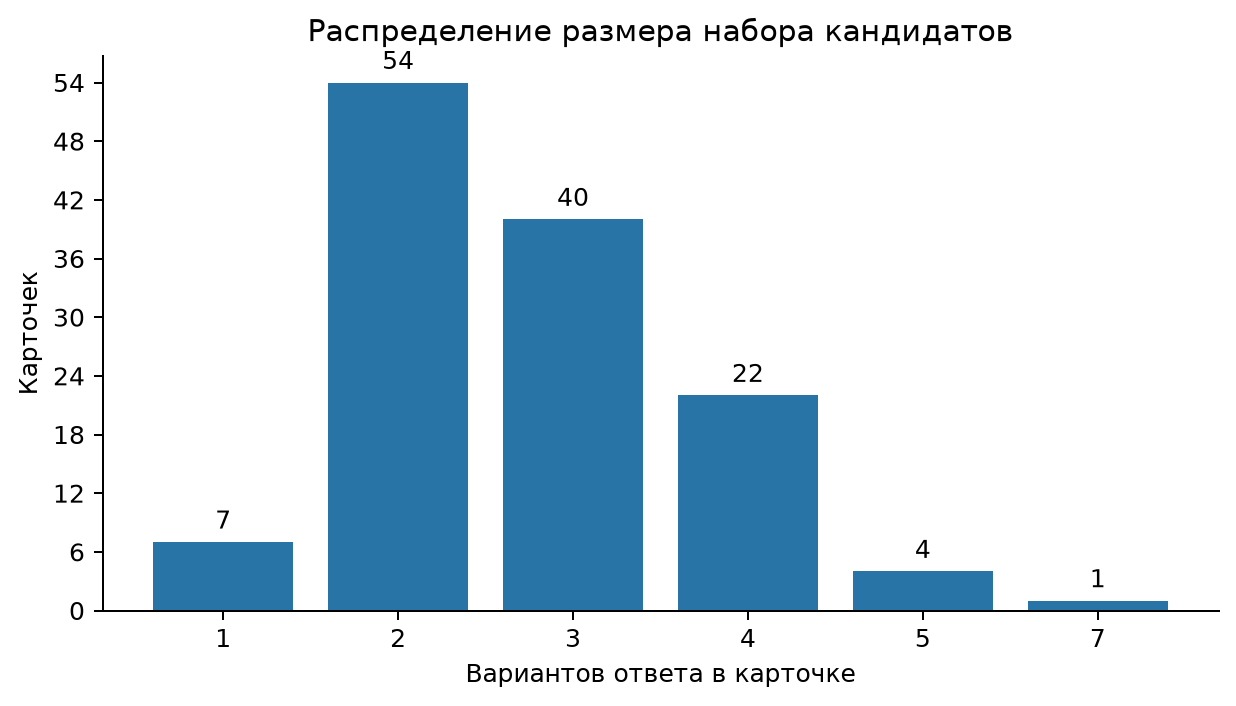

,Число ответов
count,128.000000
mean,2.734375
std,0.999877
min,1.000000
25%,2.000000
50%,3.000000
75%,3.000000
max,7.000000


In [5]:
choice_count = decisions.n_choices.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(choice_count.index.astype(str), choice_count.values, color=BLUE)
ax.bar_label(ax.containers[0], padding=3)
ax.set(xlabel='Вариантов ответа в карточке', ylabel='Карточек',
       title='Распределение размера набора кандидатов')
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
save_plot(fig, '01_choices_per_card')
display(decisions.n_choices.describe().to_frame('Число ответов'))


## 5. Длины текстов и полнота контекста

Длину сюжетного контекста измеряем по уникальным `(card_id, story)`, а не по короткому общему полю карточки.
Слова считаются простой регулярной токенизацией без лемматизации. Для строк с ⟨вариантами⟩
подсчёт включает все сохранённые варианты; это не длина одной реально показанной реплики.

,"Контекст, слов","Ответ, слов","Ввод игрока, слов"
count,581.000000,340.000000,2134.000000
mean,87.765921,1.779412,6.366448
std,54.996021,1.147597,1.553460
min,0.000000,1.000000,3.000000
25%,44.000000,1.000000,5.000000
50%,77.000000,1.000000,6.000000
75%,127.000000,2.000000,7.000000
90%,168.000000,3.000000,8.000000
95%,189.000000,4.000000,9.000000
max,246.000000,8.000000,12.000000


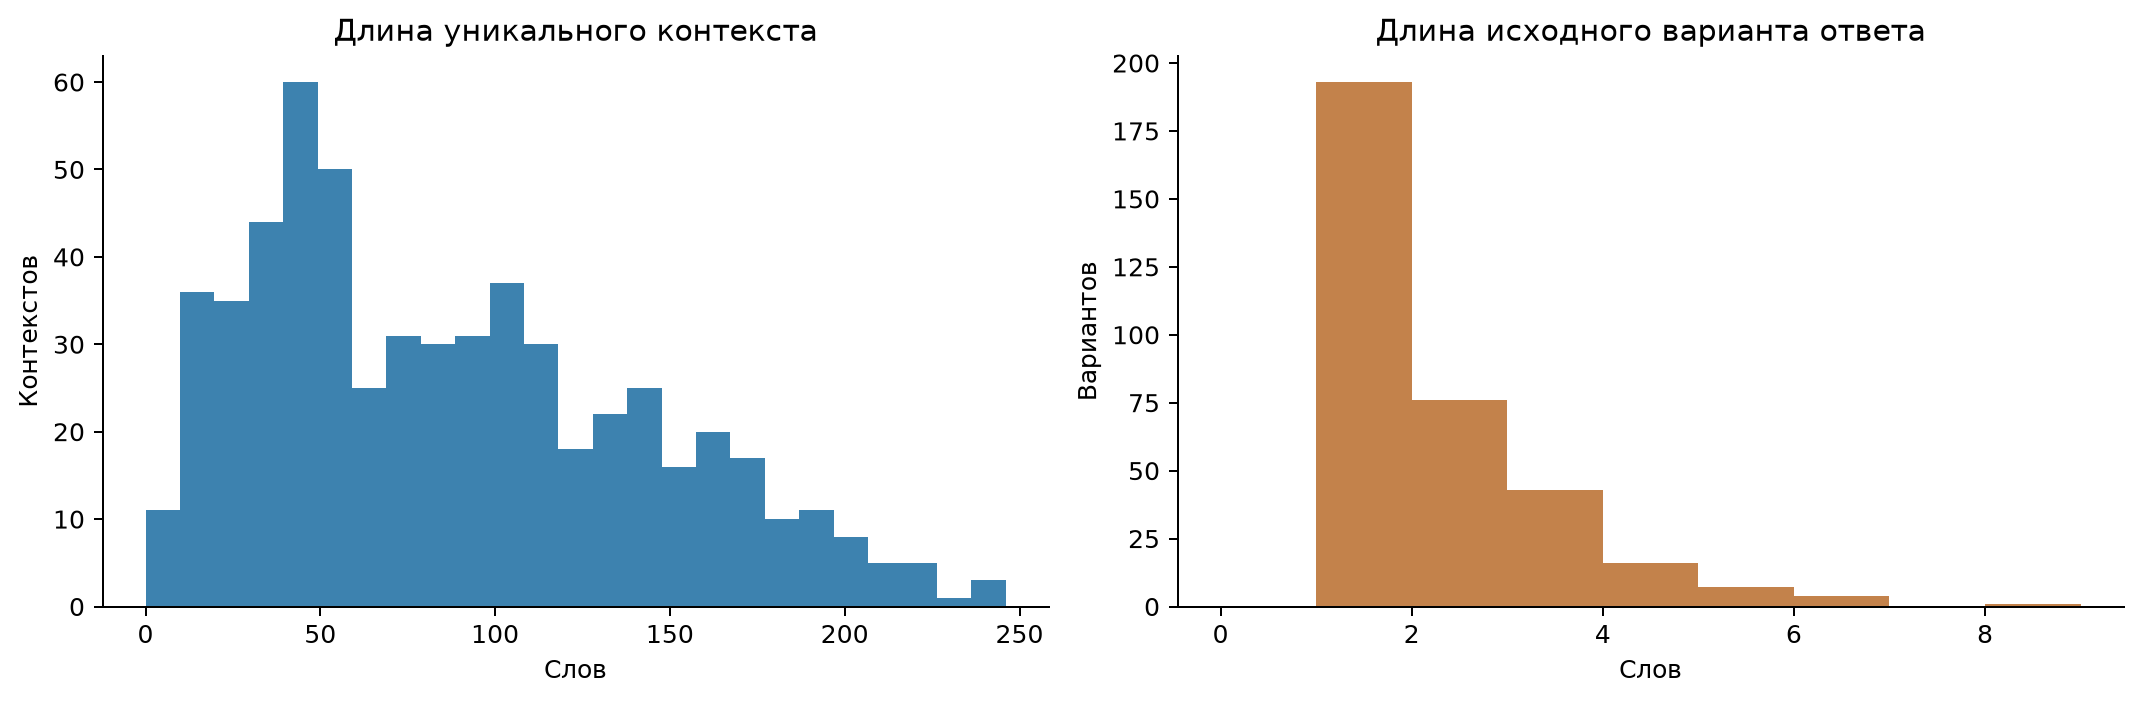

,card_id,n_words,previous_choice_text,story
638,intercept_132,246,Уклониться,"Возможно, всё зависит от ценности его имени. Если оно окажется полезным, что ж — может, я выдумаю ещё неск..."
574,intercept_132,242,Нет,"Нет. Что толку? Он наверняка уже далеко, а имя, которым назвался, без сомнения, выдумано. Нет: прежде я бы..."
606,intercept_132,239,Солгать,"Нет. Зачем? Он, несомненно, тоже невиновен, загнан в ловушку какими-нибудь ужасными обстоятельствами. Выну..."
542,intercept_132,233,Да,"Конечно, выдам. ⟨Может, уговорю их посадить его ко мне в камеру. / Небольшая месть под видом доброго дела...."
642,intercept_132,224,Уклониться,"Возможно, всё зависит от ценности его имени. Если оно окажется полезным, что ж — может, я выдумаю ещё неск..."


In [6]:
length_summary = pd.DataFrame({
    'Контекст, слов': unique_contexts.n_words.describe(percentiles=[.25,.5,.75,.9,.95]),
    'Ответ, слов': unique_choices.n_words.describe(percentiles=[.25,.5,.75,.9,.95]),
    'Ввод игрока, слов': inputs_df.n_words.describe(percentiles=[.25,.5,.75,.9,.95]),
})
display(length_summary)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(unique_contexts.n_words, bins=25, color=BLUE, alpha=.9)
axes[0].set(title='Длина уникального контекста', xlabel='Слов', ylabel='Контекстов')
axes[1].hist(unique_choices.n_words, bins=range(0, int(unique_choices.n_words.max())+2), color=ORANGE, alpha=.9)
axes[1].set(title='Длина исходного варианта ответа', xlabel='Слов', ylabel='Вариантов')
fig.tight_layout()
save_plot(fig, '02_text_lengths')
display(unique_contexts.nlargest(5,'n_words')[['card_id','n_words','previous_choice_text','story']])


## 6. Почему одного поля story не всегда достаточно

Карточка может иметь несколько предшественников. Для анализа и обучения по тексту после предыдущего выбора
используем таблицу `contexts`: она хранит предыдущую карточку, выбранный ответ и полный пришедший текст.
`cards.story` остаётся удобным общим описанием, а не подменой всех контекстов.

In [7]:
context_summary = cards_df.groupby('story_mode', dropna=False).agg(
    cards=('card_id','size'), median_variants=('n_context_variants','median'),
    max_variants=('n_context_variants','max'))
display(context_summary)
examples = cards_df.loc[cards_df.n_context_variants.gt(1)].sort_values('n_context_variants',ascending=False)
sample_card_id = examples.iloc[0].card_id
print('Пример нескольких контекстов одной карточки:', sample_card_id)
display(unique_contexts.loc[unique_contexts.card_id.eq(sample_card_id),
                           ['previous_card_id','previous_choice_text','conditions','n_words','story']].head(5))


Пример нескольких контекстов одной карточки: intercept_132


,cards,median_variants,max_variants
story_mode,,,
no_incoming_context,1,0.0,0
shared_suffix,75,3.0,128
single_context,56,1.0,1


,previous_card_id,previous_choice_text,conditions,n_words,story
542,intercept_131,Да,"[""not longgrasshooperframe"", ""not (not longgrasshooperframe)"", ""longgrasshooperframe"", ""not losttemper"", ""...",233,"Конечно, выдам. ⟨Может, уговорю их посадить его ко мне в камеру. / Небольшая месть под видом доброго дела...."
543,intercept_131,Да,"[""not longgrasshooperframe"", ""not (not longgrasshooperframe)"", ""longgrasshooperframe"", ""not losttemper""]",187,"Конечно, выдам. ⟨Может, уговорю их посадить его ко мне в камеру. / Небольшая месть под видом доброго дела...."
544,intercept_131,Да,"[""not longgrasshooperframe"", ""not (not longgrasshooperframe)"", ""longgrasshooperframe"", ""not (not losttempe...",200,"Конечно, выдам. ⟨Может, уговорю их посадить его ко мне в камеру. / Небольшая месть под видом доброго дела...."
545,intercept_131,Да,"[""not longgrasshooperframe"", ""not (not longgrasshooperframe)"", ""longgrasshooperframe"", ""not (not losttempe...",154,"Конечно, выдам. ⟨Может, уговорю их посадить его ко мне в камеру. / Небольшая месть под видом доброго дела...."
546,intercept_131,Да,"[""not longgrasshooperframe"", ""not (not longgrasshooperframe)"", ""not (longgrasshooperframe)"", ""not losttemp...",211,"Конечно, выдам. ⟨Может, уговорю их посадить его ко мне в камеру. / Небольшая месть под видом доброго дела...."


## 7. Повторяющиеся ответы и неоднозначность формулировок

Частоты показывают авторские формулировки, а не популярность действий у игроков.
Один и тот же ответ («Да», «Нет», «Солгать») в разных сценах имеет разный смысл.
Проверяем также совпадения формулировок внутри одной карточки, сохраняя условия доступности и назначения.

Карточек с повтором текста ответа: 9


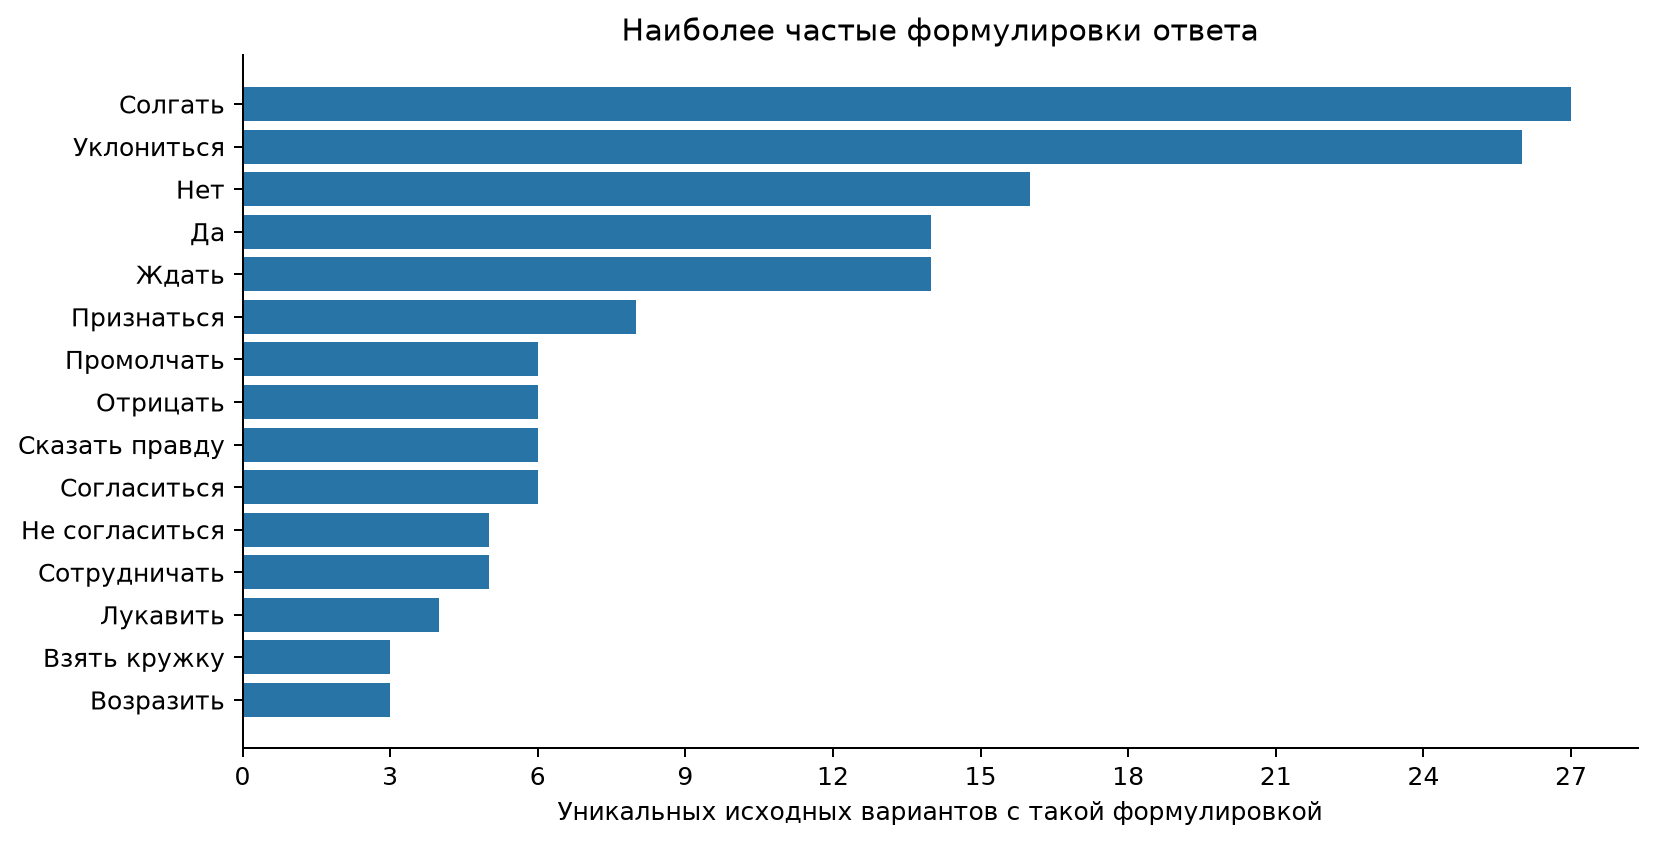

,card_id,choice_id,choice_text,conditions,n_targets,n_routes
71,intercept_023,choice:324,Не согласиться,"[""not drugged""]",1,1
72,intercept_023,choice:328,Не согласиться,"[""drugged""]",1,1
73,intercept_023,choice:332,Солгать,"[""drugged""]",1,1
74,intercept_023,choice:333,Солгать,"[""not drugged""]",1,1
75,intercept_023,choice:334,Уклониться,"[""drugged""]",1,1
76,intercept_023,choice:336,Уклониться,"[""not drugged""]",1,1
78,intercept_024,choice:348,Нет,"[""not drugged""]",1,1
79,intercept_024,choice:353,Нет,"[""drugged""]",1,1
80,intercept_024,choice:360,Уклониться,"[""not drugged""]",1,1
81,intercept_024,choice:363,Уклониться,"[""drugged""]",1,1


In [8]:
label_counts = unique_choices.choice_text.value_counts()
fig, ax = plt.subplots(figsize=(10, 5))
top_labels = label_counts.head(15).sort_values()
ax.barh(top_labels.index, top_labels.values, color=BLUE)
ax.set(xlabel='Уникальных исходных вариантов с такой формулировкой',
       title='Наиболее частые формулировки ответа')
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
save_plot(fig, '03_common_choice_texts')

within_card_duplicates = choices_df[choices_df.duplicated(['card_id','choice_text'],keep=False)].sort_values(['card_id','choice_text'])
print('Карточек с повтором текста ответа:', within_card_duplicates.card_id.nunique())
display(within_card_duplicates[['card_id','choice_id','choice_text','conditions','n_targets','n_routes']])


## 8. Лексически похожие варианты внутри карточки

TF-IDF по символьным n-граммам длины 2–5 даёт **описательную лексическую** близость.
Это не семантическая разметка, не качество будущей модели и не доказательство взаимозаменяемости ответов.
Высокие значения помогают выбрать пары для ручной проверки вместе с контекстом и условиями.

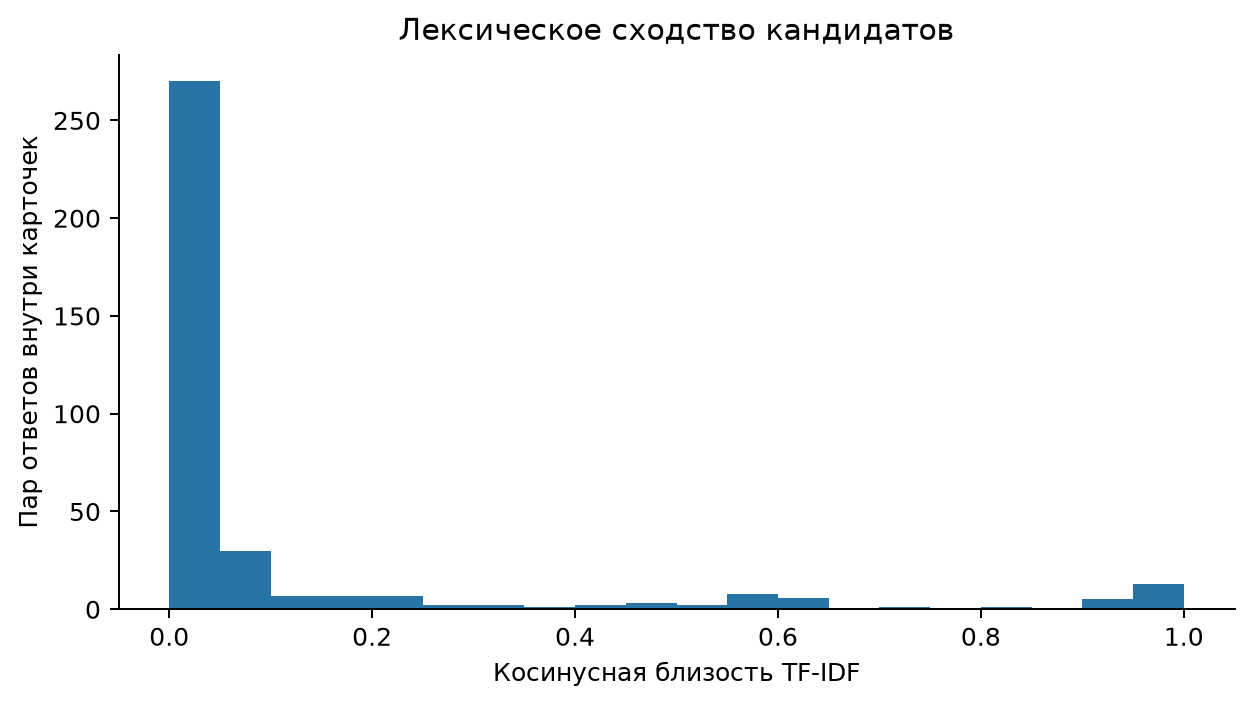

,card_id,left_id,right_id,left_text,right_text,cosine,same_text,left_conditions,right_conditions
309,intercept_100,choice:1297,choice:1302,Проявить оптимизм,Проявить оптимизм,1.0,True,"[""not framedhooper""]","[""framedhooper""]"
299,intercept_095,choice:1233,choice:1237,Отрицать,Отрицать,1.0,True,"[""not framedhooper""]","[""framedhooper""]"
320,intercept_105,choice:1355,choice:1421,Ждать,Ждать,1.0,True,"[""hooperClueType > NONE""]","[""hooperClueType == NONE""]"
200,intercept_055,choice:758,choice:763,Ждать,Ждать,1.0,True,"[""putmein""]","[""not putmein""]"
115,intercept_024,choice:360,choice:363,Уклониться,Уклониться,1.0,True,"[""not drugged""]","[""drugged""]"
105,intercept_023,choice:334,choice:336,Уклониться,Уклониться,1.0,True,"[""drugged""]","[""not drugged""]"
142,intercept_031,choice:494,choice:495,Лукавить,Лукавить,1.0,True,"[""not drugged""]","[""drugged""]"
100,intercept_023,choice:332,choice:333,Солгать,Солгать,1.0,True,"[""drugged""]","[""not drugged""]"
110,intercept_024,choice:348,choice:353,Нет,Нет,1.0,True,"[""not drugged""]","[""drugged""]"
149,intercept_034,choice:529,choice:533,Нет,Нет,1.0,True,"[""not drugged""]","[""drugged""]"


In [9]:
vectorizer = TfidfVectorizer(analyzer='char_wb', ngram_range=(2,5), lowercase=True)
vectorizer.fit(unique_choices.choice_text)
choice_vectors = vectorizer.transform(choices_df.choice_text)
pair_rows = []
for card_id, group in choices_df.groupby('card_id',sort=False):
    for left, right in itertools.combinations(group.index,2):
        a,b = choices_df.loc[left],choices_df.loc[right]
        score = float(np.clip(choice_vectors[left].multiply(choice_vectors[right]).sum(), 0.0, 1.0))
        pair_rows.append({'card_id':card_id, 'left_id':a.choice_id, 'right_id':b.choice_id,
                          'left_text':a.choice_text, 'right_text':b.choice_text,
                          'cosine':score, 'same_text':a.choice_text==b.choice_text,
                          'left_conditions':a.conditions, 'right_conditions':b.conditions})
choice_pairs = pd.DataFrame(pair_rows)
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(choice_pairs.cosine, bins=np.linspace(0,1,21), color=BLUE)
ax.set(xlabel='Косинусная близость TF-IDF', ylabel='Пар ответов внутри карточек',
       title='Лексическое сходство кандидатов')
save_plot(fig, '04_choice_similarity')
display(choice_pairs.sort_values('cosine',ascending=False).head(12))


## 9. Условные переходы: ответ не всегда задаёт одно назначение

Различаем число автоматических маршрутов и число **разных целевых карточек**.
Несколько путей могут приводить в одну карточку, показывая разный сюжетный текст.
Условия здесь сохранены как строки Ink; их истинность не проверяется.

Маршрутов с сохранёнными условиями: 459


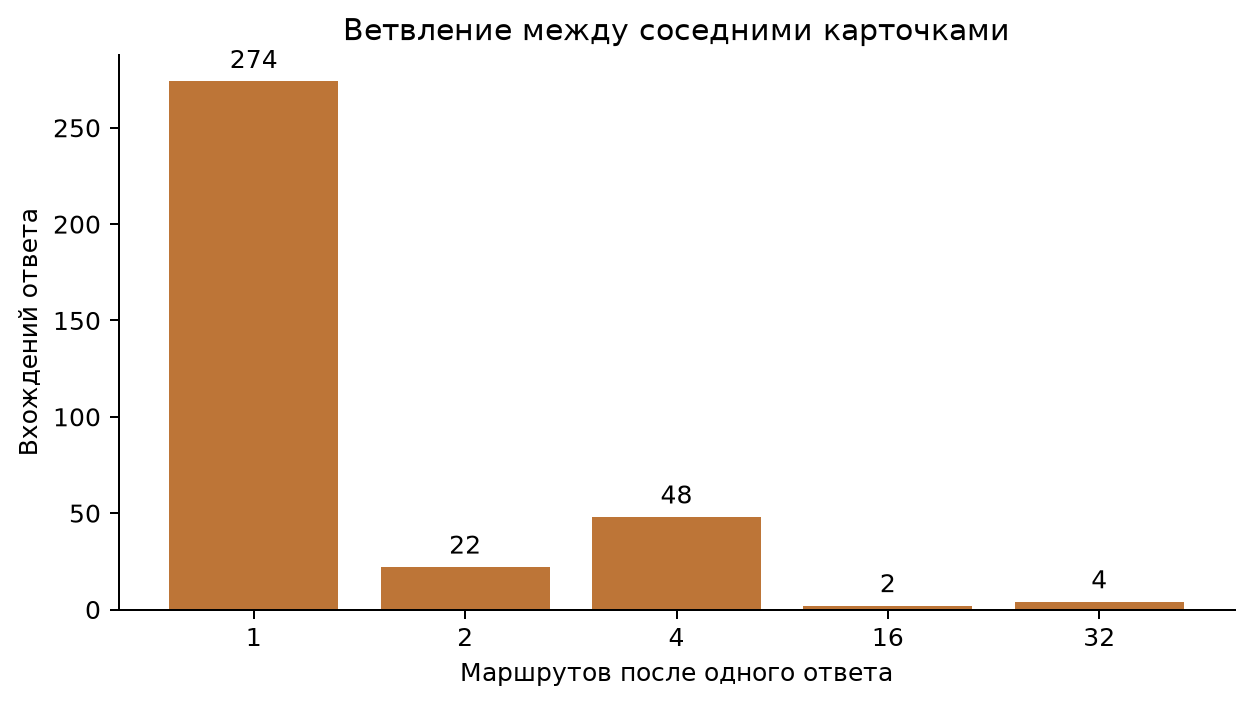

,card_id,choice_id,choice_text,n_targets,n_routes,conditions
22,intercept_008,choice:163,Понаблюдать за ним,2,2,[]
23,intercept_008,choice:166,Ждать,2,2,[]
24,intercept_008,choice:169,Улыбнуться,2,2,"[""not disagree""]"
61,intercept_020,choice:276,Уклониться,2,2,[]
230,intercept_079,choice:1093,Ждать,2,2,[]
262,intercept_093,choice:1209,Ждать,2,2,[]


In [10]:
route_counts = choices_df.n_routes.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(route_counts.index.astype(str),route_counts.values,color=ORANGE)
ax.bar_label(ax.containers[0],padding=3)
ax.set(xlabel='Маршрутов после одного ответа', ylabel='Вхождений ответа',
       title='Ветвление между соседними карточками')
save_plot(fig, '05_routes_per_choice')
print('Маршрутов с сохранёнными условиями:', int(routes_df.n_conditions.gt(0).sum()))
display(choices_df.loc[choices_df.n_targets.gt(1),
                      ['card_id','choice_id','choice_text','n_targets','n_routes','conditions']])


## 10. Структура графа карточек

Для топологии используем ориентированный граф без параллельных рёбер: несколько маршрутов одной пары карточек
образуют одно ребро. Поэтому число рёбер графа меньше числа маршрутов.
Достижимость считается без исполнения условий и означает только наличие структурного пути.

In [11]:
G = nx.DiGraph()
G.add_nodes_from(cards_df.card_id)
G.add_edges_from(routes_df[['from_card_id','to_card_id']].itertuples(index=False,name=None))
entry_ids = [e['target_id'] for e in dataset['entry_routes']]
reachable = set(entry_ids)
for entry in entry_ids:
    reachable.update(nx.descendants(G,entry))
assert reachable == set(cards_df.loc[cards_df.reachable_from_start,'card_id'])

strong_components = list(nx.strongly_connected_components(G))
nontrivial_components = [component for component in strong_components if len(component)>1]
self_loops = list(nx.selfloop_edges(G))
graph_metrics = pd.Series({
    'Вершин':G.number_of_nodes(), 'Разных направленных рёбер':G.number_of_edges(),
    'Слабосвязных компонент':nx.number_weakly_connected_components(G),
    'Структурно достижимых карточек':len(reachable),
    'Структурно недостижимых карточек':G.number_of_nodes()-len(reachable),
    'Петель на саму карточку':len(self_loops),
    'Сильно связных компонент размера > 1':len(nontrivial_components),
    'Размер наибольшей сильно связной компоненты':max(map(len,strong_components)),
},name='Значение')
display(graph_metrics.to_frame())
display(cards_df.loc[~cards_df.card_id.isin(reachable),
                     ['card_id','section','source_line','n_choices','story']])


,Значение
Вершин,132
Разных направленных рёбер,220
Слабосвязных компонент,1
Структурно достижимых карточек,131
Структурно недостижимых карточек,1
Петель на саму карточку,5
Сильно связных компонент размера > 1,1
Размер наибольшей сильно связной компоненты,2


,card_id,section,source_line,n_choices,story
126,intercept_127,harris_threatens_lynching,1582,2,


## 11. Обзор топологии

На рисунке только структура связей, а не порядок чтения текста. Положение вершин рассчитано автоматически.
Зелёным отмечены сюжетные финалы, серым — карточки без структурного пути от начала.
Детальная карта с текстом сохранена отдельно в `previous_work` и исключена из Git.

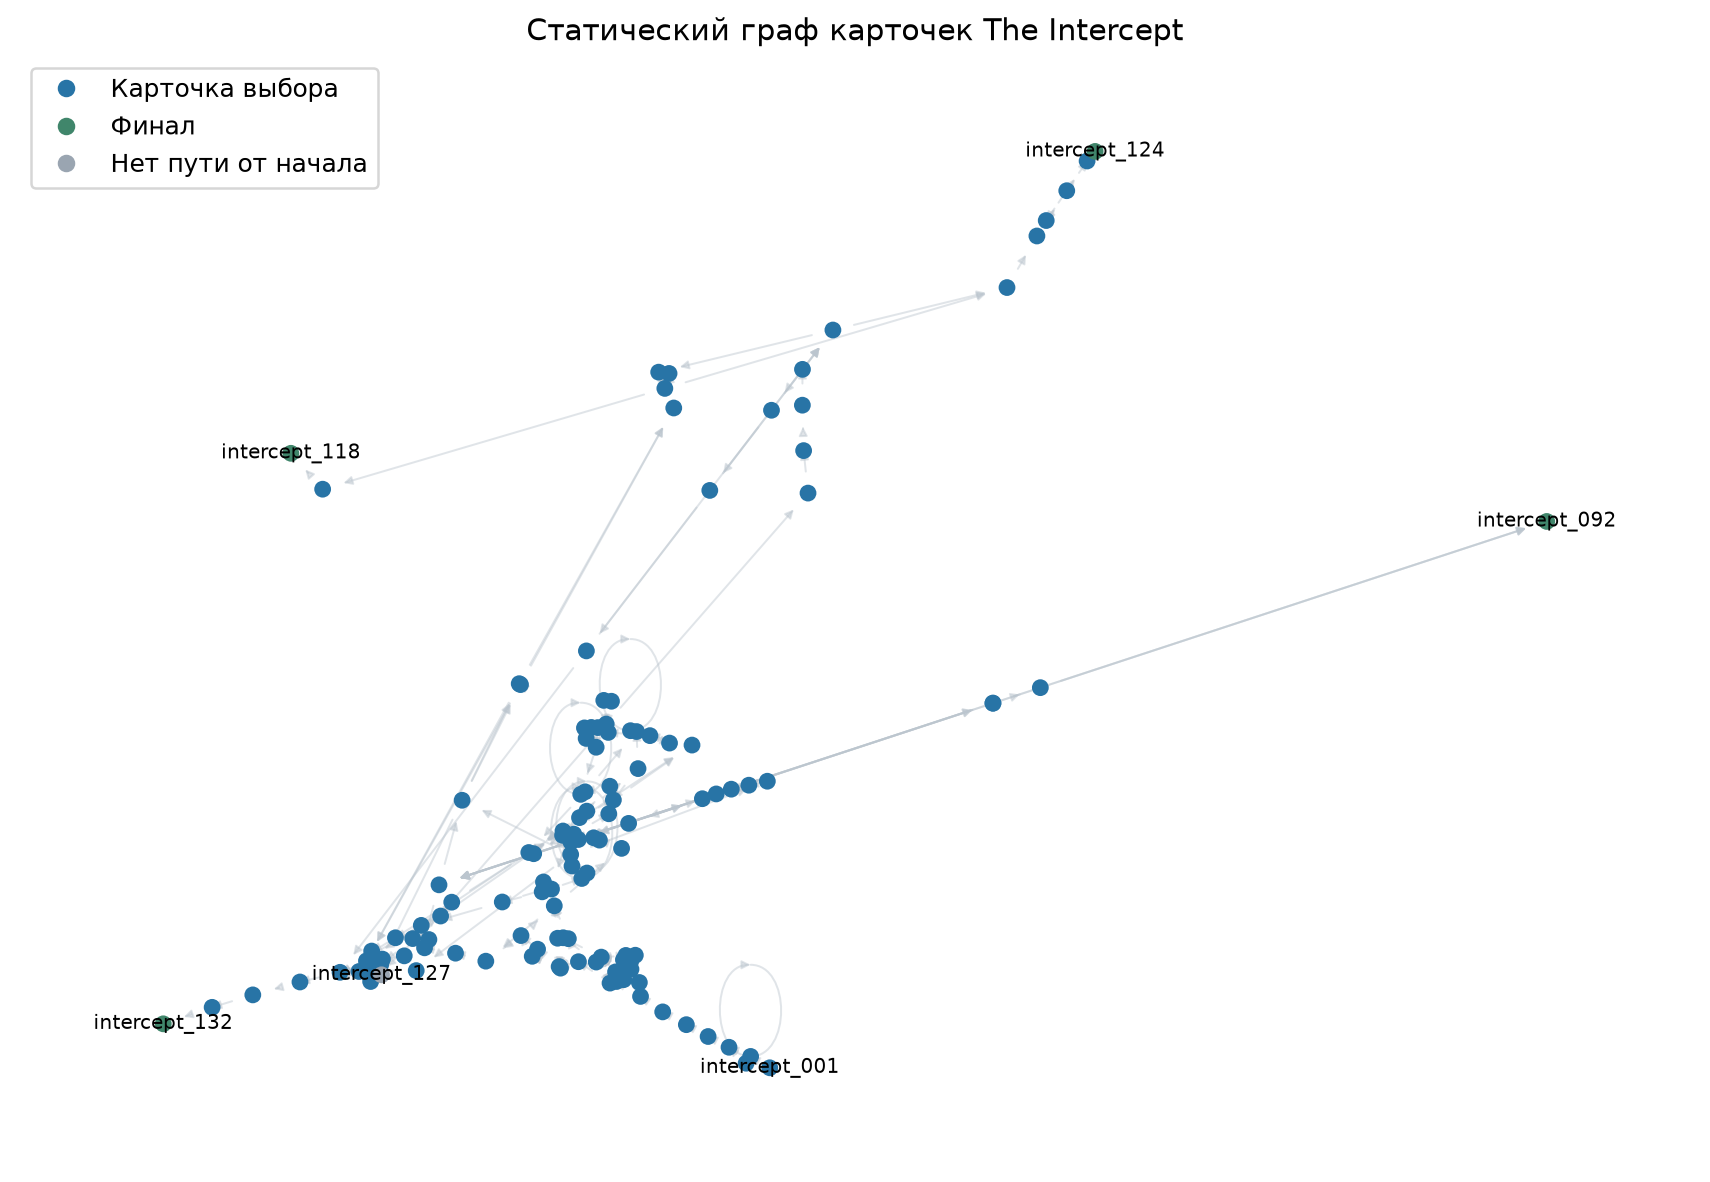

In [12]:
positions = nx.spring_layout(G,seed=42,iterations=140)
ending_ids = set(endings.card_id)
node_colors = [GREEN if node in ending_ids else GREY if node not in reachable else BLUE for node in G]
fig, ax = plt.subplots(figsize=(12,8))
nx.draw_networkx_edges(G,positions,ax=ax,edge_color='#bbc5ce',alpha=.45,arrows=True,arrowsize=7,width=.8)
nx.draw_networkx_nodes(G,positions,ax=ax,node_color=node_colors,node_size=45,linewidths=0)
important = {node:node for node in G if node in ending_ids or node in entry_ids or node not in reachable}
nx.draw_networkx_labels(G,positions,labels=important,ax=ax,font_size=8,font_family='DejaVu Sans')
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([],[],marker='o',linestyle='',color=BLUE,label='Карточка выбора'),
                   Line2D([],[],marker='o',linestyle='',color=GREEN,label='Финал'),
                   Line2D([],[],marker='o',linestyle='',color=GREY,label='Нет пути от начала')],loc='upper left')
ax.set_title('Статический граф карточек The Intercept')
ax.axis('off')
save_plot(fig, '06_card_graph')


## 12. Возвраты, циклы и расстояние до финала

Кратчайший путь измеряем числом выборов между карточками. Автоматические абзацы уже свёрнуты в маршрут.
Из-за циклов единственную максимальную длину прохождения не вычисляем.
Петля в статическом графе не означает бесконечное прохождение: `once_only` и состояние игры могут его ограничивать.

Петли: [('intercept_002', 'intercept_002'), ('intercept_060', 'intercept_060'), ('intercept_067', 'intercept_067'), ('intercept_076', 'intercept_076'), ('intercept_077', 'intercept_077')]
Циклические группы карточек: [['intercept_076', 'intercept_077']]


,card_id,source_line,story,min_choices_from_start
91,intercept_092,1195,"Лучше жить в бегах, чем умереть на вертеле. Крадучись вдоль ограды⟨, чувствуя в кармане тяжесть детали «Бо...",30
117,intercept_118,1501,"Нужно заново настроить и запустить «Бомбу».\n\nПора взяться за задачу, которую я способен решить.",30
123,intercept_124,1552,Он ведёт меня через двор. Обратно к бараку № 5 — чтобы меня снова расшифровали и разобрали на части.,31
131,intercept_132,1682,Он рывком поднимает меня на ноги.\n\n«Вам обязательно всё изобретать заново».\n\nС этими словами он выводи...,20


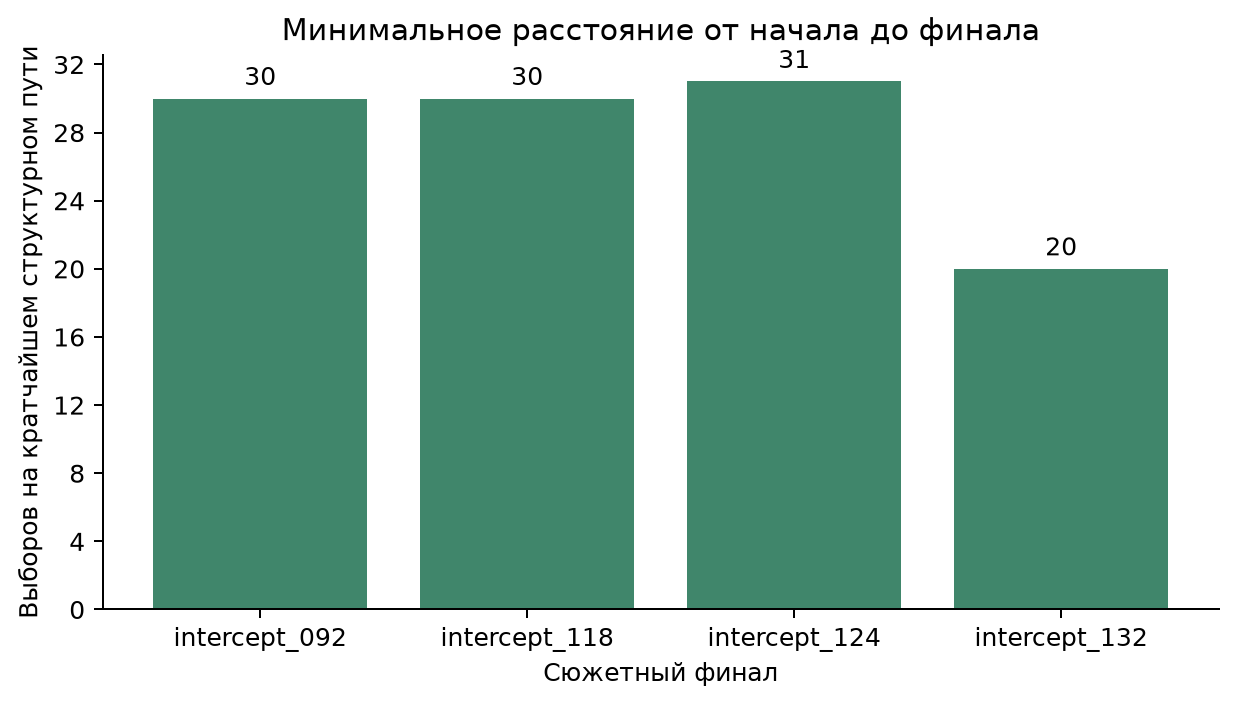

In [13]:
shortest = {}
for entry in entry_ids:
    for node,distance in nx.single_source_shortest_path_length(G,entry).items():
        shortest[node] = min(shortest.get(node,float('inf')),distance)
ending_distances = endings[['card_id','source_line','story']].copy()
ending_distances['min_choices_from_start'] = ending_distances.card_id.map(shortest)
display(ending_distances)
print('Петли:',self_loops)
print('Циклические группы карточек:',[sorted(component) for component in nontrivial_components])
fig,ax = plt.subplots(figsize=(8,4))
ax.bar(ending_distances.card_id,ending_distances.min_choices_from_start,color=GREEN)
ax.bar_label(ax.containers[0],padding=3)
ax.set(xlabel='Сюжетный финал',ylabel='Выборов на кратчайшем структурном пути',
       title='Минимальное расстояние от начала до финала')
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
save_plot(fig,'07_shortest_paths_to_endings')


## 13. Повторные исходные группы выбора

В выборке одна история, теперь дополненная свободными вводами и метками «вариант / нет соответствия».
EDA описывает эти примеры; качество модели нужно измерять отдельным экспериментом на отложенных группах.

Повтор одной исходной группы выбора в разных контекстах — допустимая структура подисторий.
Для будущего эксперимента нельзя случайно разнести такие копии между train и test и считать их независимыми.
Поле `source_group_id` позволяет контролировать это совпадение. Для проверки переноса между историями нужны другие истории.

In [14]:
reused_groups = (decisions.groupby('source_group_id',dropna=False)
                .agg(n_cards=('card_id','size'),cards=('card_id',list))
                .query('n_cards > 1'))
display(reused_groups)
source_occurrences = choices_df.groupby('choice_id').size()
print('Исходных вариантов, повторённых в нескольких карточках:',int(source_occurrences.gt(1).sum()))
print('Дополнительных вхождений из-за контекстов:',len(choices_df)-choices_df.choice_id.nunique())
print('Повторных пар (карточка, текст) среди контекстов:',len(contexts_df)-len(unique_contexts))


Исходных вариантов, повторённых в нескольких карточках: 5
Дополнительных вхождений из-за контекстов: 10
Повторных пар (карточка, текст) среди контекстов: 90


,n_cards,cards
source_group_id,,
intercept_group_5a9cc886618a,3,"[intercept_010, intercept_011, intercept_012]"
intercept_group_9b69cda05d81,3,"[intercept_013, intercept_014, intercept_015]"


## 14. Качество разметки свободного ввода

Проверяем правильность ссылок, покрытие всех авторских вариантов, наличие неподходящих вводов,
пустые строки, повторы и соответствие JSON отдельной таблице CSV. `null` — полноценная целевая метка,
а не пропуск разметки. Отсутствие контекста проверяется отдельно и не подменяется отсутствием метки.
Количество примеров сравнивается с правилами в `metadata.matching`, а не с константами в коде анализа.
Эти проверки подтверждают структуру разметки, но не доказывают семантическую правильность каждого примера.

In [15]:
positive_counts = (inputs_df.loc[inputs_df.is_match].groupby(['card_id','choice_id'])
                   .size().rename('n_inputs').reset_index())
choice_input_coverage = choices_df[['card_id','choice_id','choice_text','conditions']].merge(
    cards_df[['card_id','source_group_id']],on='card_id',how='left',validate='many_to_one')
choice_input_coverage = choice_input_coverage.merge(positive_counts, how='left', on=['card_id','choice_id'])
choice_input_coverage['n_inputs'] = choice_input_coverage.n_inputs.fillna(0).astype(int)

input_card_counts = inputs_df.groupby('card_id').agg(
    n_inputs=('input_id','size'), matched_inputs=('is_match','sum'),
    used_contexts=('context_id','nunique'), unique_input_texts=('normalized_text','nunique'))
input_card_counts['unmatched_inputs'] = input_card_counts.n_inputs - input_card_counts.matched_inputs
card_input_coverage = cards_df[['card_id','kind','n_choices','source_group_id','reachable_from_start']].merge(
    input_card_counts, how='left', on='card_id')
count_columns = ['n_inputs','matched_inputs','unmatched_inputs','used_contexts','unique_input_texts']
card_input_coverage[count_columns] = card_input_coverage[count_columns].fillna(0).astype(int)
decision_input_coverage = card_input_coverage.query("kind == 'decision'")

duplicate_inputs = (inputs_df.groupby('normalized_text',sort=False)
    .agg(n_inputs=('input_id','size'), n_cards=('card_id','nunique'),
         n_source_choices=('choice_id','nunique'), has_null=('is_match',lambda s: bool((~s).any())),
         text=('text','first'), cards=('card_id',lambda s: '|'.join(sorted(set(s)))),
         choice_ids=('choice_id',lambda s: '|'.join(sorted(set(s.dropna())))))
    .query('n_inputs > 1').reset_index())

input_csv = pd.read_csv(ROOT/'data'/'user_inputs.csv', dtype=str, keep_default_na=False)
csv_columns = list(input_csv.columns)
csv_matches = set(csv_columns) <= set(inputs_df.columns) and input_csv.equals(
    inputs_df[csv_columns].fillna('').astype(str))
spec = dataset.get('metadata', {}).get('matching', {})
expected_per_choice = spec.get('examples_per_choice')
expected_null_per_card = spec.get('unmatched_per_decision')
contextless_card_ids = {c['id'] for c in dataset['cards']
                       if not c['previous'] and c['id'] not in entry_ids}
input_checks = {
    'id вводов уникальны': inputs_df.input_id.is_unique,
    'вводы не пустые': inputs_df.text.str.strip().ne('').all(),
    'метка ссылается на вариант своей карточки': all(
        not row.is_match or row.choice_id in {o['id'] for o in by_id[row.card_id]['choices']}
        for row in inputs_df.itertuples()),
    'контекст ведёт в карточку ввода': all(
        pd.isna(row.context_id) or context_lookup.get(row.context_id, {}).get('card_id') == row.card_id
        for row in inputs_df.itertuples()),
    'отсутствие ссылки на контекст объясняется исходным графом':
        set(inputs_df.loc[inputs_df.context_id.isna(),'card_id']) <= contextless_card_ids,
    'каждый авторский вариант покрыт вводами': choice_input_coverage.n_inputs.gt(0).all(),
    'каждая карточка выбора имеет неподходящие вводы': decision_input_coverage.unmatched_inputs.gt(0).all(),
    'финалы не имеют вводов': card_input_coverage.query("kind == 'ending'").n_inputs.eq(0).all(),
    'в карточке нет повторов ввода': not inputs_df.duplicated(['card_id','normalized_text']).any(),
    'повторы между карточками относятся только к одному исходному варианту':
        duplicate_inputs.n_source_choices.eq(1).all() and not duplicate_inputs.has_null.any(),
    'JSON и CSV совпадают, включая пустые метки': csv_matches,
    'число примеров соответствует metadata.matching':
        spec.get('inputs') == len(inputs_df) and spec.get('matched') == int(inputs_df.is_match.sum())
        and spec.get('unmatched') == int((~inputs_df.is_match).sum()),
}
if expected_per_choice is not None:
    input_checks['соблюдено заданное число вводов на вариант'] = choice_input_coverage.n_inputs.eq(expected_per_choice).all()
if expected_null_per_card is not None:
    input_checks['соблюдено заданное число null на карточку'] = decision_input_coverage.unmatched_inputs.eq(expected_null_per_card).all()
input_quality_checks = pd.DataFrame({
    'Проверка': list(input_checks), 'Пройдена': [bool(v) for v in input_checks.values()]})
display(input_quality_checks)
assert all(input_checks.values()), 'Нарушена целостность разметки ввода'
display(inputs_df.loc[~inputs_df.has_context, ['input_id','card_id','text','choice_id','context_id']])


,Проверка,Пройдена
0,id вводов уникальны,True
1,вводы не пустые,True
2,метка ссылается на вариант своей карточки,True
3,контекст ведёт в карточку ввода,True
4,отсутствие ссылки на контекст объясняется исходным графом,True
5,каждый авторский вариант покрыт вводами,True
6,каждая карточка выбора имеет неподходящие вводы,True
7,финалы не имеют вводов,True
8,в карточке нет повторов ввода,True
9,повторы между карточками относятся только к одному исходному варианту,True


,input_id,card_id,text,choice_id,context_id
2069,input_127_001,intercept_127,Я бросил её в высокую траву у Хупера.,choice:1582,None
2070,input_127_002,intercept_127,Признаюсь в неудачной попытке подставить коллегу.,choice:1582,None
2071,input_127_003,intercept_127,"Барабан за его палаткой, это я туда закинул.",choice:1582,None
2072,input_127_004,intercept_127,Скажу правду о детали в кустах.,choice:1582,None
2073,input_127_005,intercept_127,"Не буду оговаривать Хупера, сам назову своё действие.",choice:1582,None
2074,input_127_006,intercept_127,"Скажу, будто видел, как Хупер бросил её за палатку.",choice:1587,None
2075,input_127_007,intercept_127,"Оговорю его, назвав настоящий тайник в траве.",choice:1587,None
2076,input_127_008,intercept_127,"Совру, что деталь спрятал там коллега.",choice:1587,None
2077,input_127_009,intercept_127,"Пусть думают, что барабан в кустах доказывает вину Хупера.",choice:1587,None
2078,input_127_010,intercept_127,"Место назову верное, но того, кто бросил, выдумаю.",choice:1587,None


## 15. Баланс меток и покрытие вариантов

Сравниваем доли подходящих и неподходящих вводов, а также количество примеров у каждого варианта.
Равное число подходящих примеров на вариант — правило состава датасета, а не наблюдаемое поведение людей.
Доля `null` в отдельной карточке зависит от числа вариантов: при фиксированных 3 неподходящих вводах
и 5 примерах на вариант она равна `3 / (5 × число вариантов + 3)`.

,n_inputs,share_pct
label_type,,
Есть соответствие,1750,82.005623
Нет соответствия (null),384,17.994377


,cards,inputs,null_inputs,null_share_pct
n_choices,,,,
1,7,56,21,37.500000
2,54,702,162,23.076923
3,40,720,120,16.666667
4,22,506,66,13.043478
5,4,112,12,10.714286
7,1,38,3,7.894737


,Вводов на авторский вариант
count,350.0
mean,5.0
std,0.0
min,5.0
25%,5.0
50%,5.0
75%,5.0
max,5.0


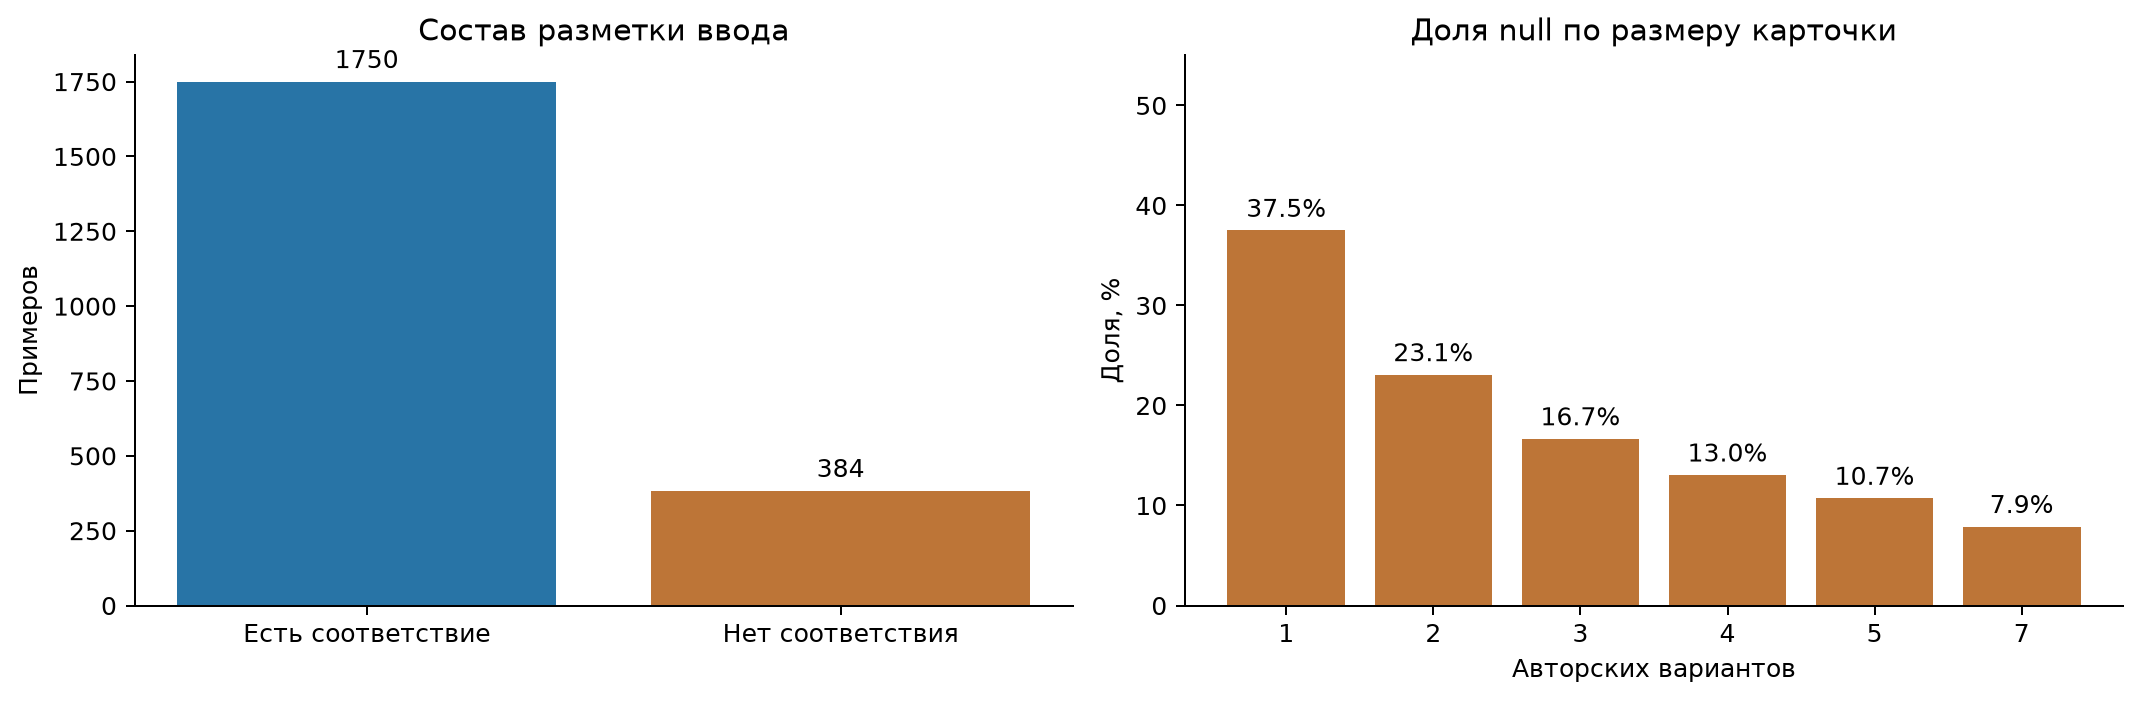

In [16]:
label_balance = (inputs_df.groupby('label_type',sort=False).size().rename('n_inputs').to_frame())
label_balance['share_pct'] = 100 * label_balance.n_inputs / len(inputs_df)
coverage_by_size = decision_input_coverage.groupby('n_choices').agg(
    cards=('card_id','size'), inputs=('n_inputs','sum'), null_inputs=('unmatched_inputs','sum'))
coverage_by_size['null_share_pct'] = 100 * coverage_by_size.null_inputs / coverage_by_size.inputs
display(label_balance)
display(coverage_by_size)
display(choice_input_coverage.n_inputs.describe().to_frame('Вводов на авторский вариант'))

fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].bar(['Есть соответствие','Нет соответствия'],
            [int(inputs_df.is_match.sum()), int((~inputs_df.is_match).sum())], color=[BLUE,ORANGE])
axes[0].bar_label(axes[0].containers[0],padding=3)
axes[0].set(title='Состав разметки ввода',ylabel='Примеров')
axes[1].bar(coverage_by_size.index.astype(str),coverage_by_size.null_share_pct,color=ORANGE)
axes[1].bar_label(axes[1].containers[0],fmt='%.1f%%',padding=3)
axes[1].set(title='Доля null по размеру карточки',xlabel='Авторских вариантов',ylabel='Доля, %',ylim=(0,55))
fig.tight_layout()
save_plot(fig,'08_input_labels_and_coverage')


## 16. Длины и формулировки вводов игроков

Сравниваем длины подходящих и неподходящих вводов, исходных вариантов и контекста.
Единицы распределений различаются: вводы считаются по записям, авторские варианты — по уникальному `choice_id`,
контексты — по уникальным `(card_id, story)`. Дополнительно считаем наличие отрицаний и вопросительных знаков.
Это простые лексические признаки, а не автоматическая проверка качества или сложности разметки.

Вводов, дословно совпадающих со своим авторским вариантом: 1


,inputs,min_words,median_words,mean_words,max_words,median_chars,negation_share,question_share
label_type,,,,,,,,
Есть соответствие,1750,3,7.0,6.589,12,42.0,0.303,0.020
Нет соответствия (null),384,3,5.0,5.352,10,36.0,0.010,0.174


,card_id,text,choice_text,label_type,n_words
814,intercept_043,"Вы знаете о моей слабости, но это не значит, что украл я.",Настаивать на своём,Есть соответствие,12
1022,intercept_057,"На самом деле боюсь и не знаю, что делать, но это скрою.",Солгать,Есть соответствие,12
1156,intercept_065,"Не буду спорить с его оценкой, попрошу не отдавать меня на казнь.",Принять,Есть соответствие,12
220,intercept_013,"Нас четверо, значит, посмотрю на это как на задачу о шансах.",Рассчитать шансы,Есть соответствие,11
238,intercept_014,"Нас четверо, значит, посмотрю на это как на задачу о шансах.",Рассчитать шансы,Есть соответствие,11
256,intercept_015,"Нас четверо, значит, посмотрю на это как на задачу о шансах.",Рассчитать шансы,Есть соответствие,11


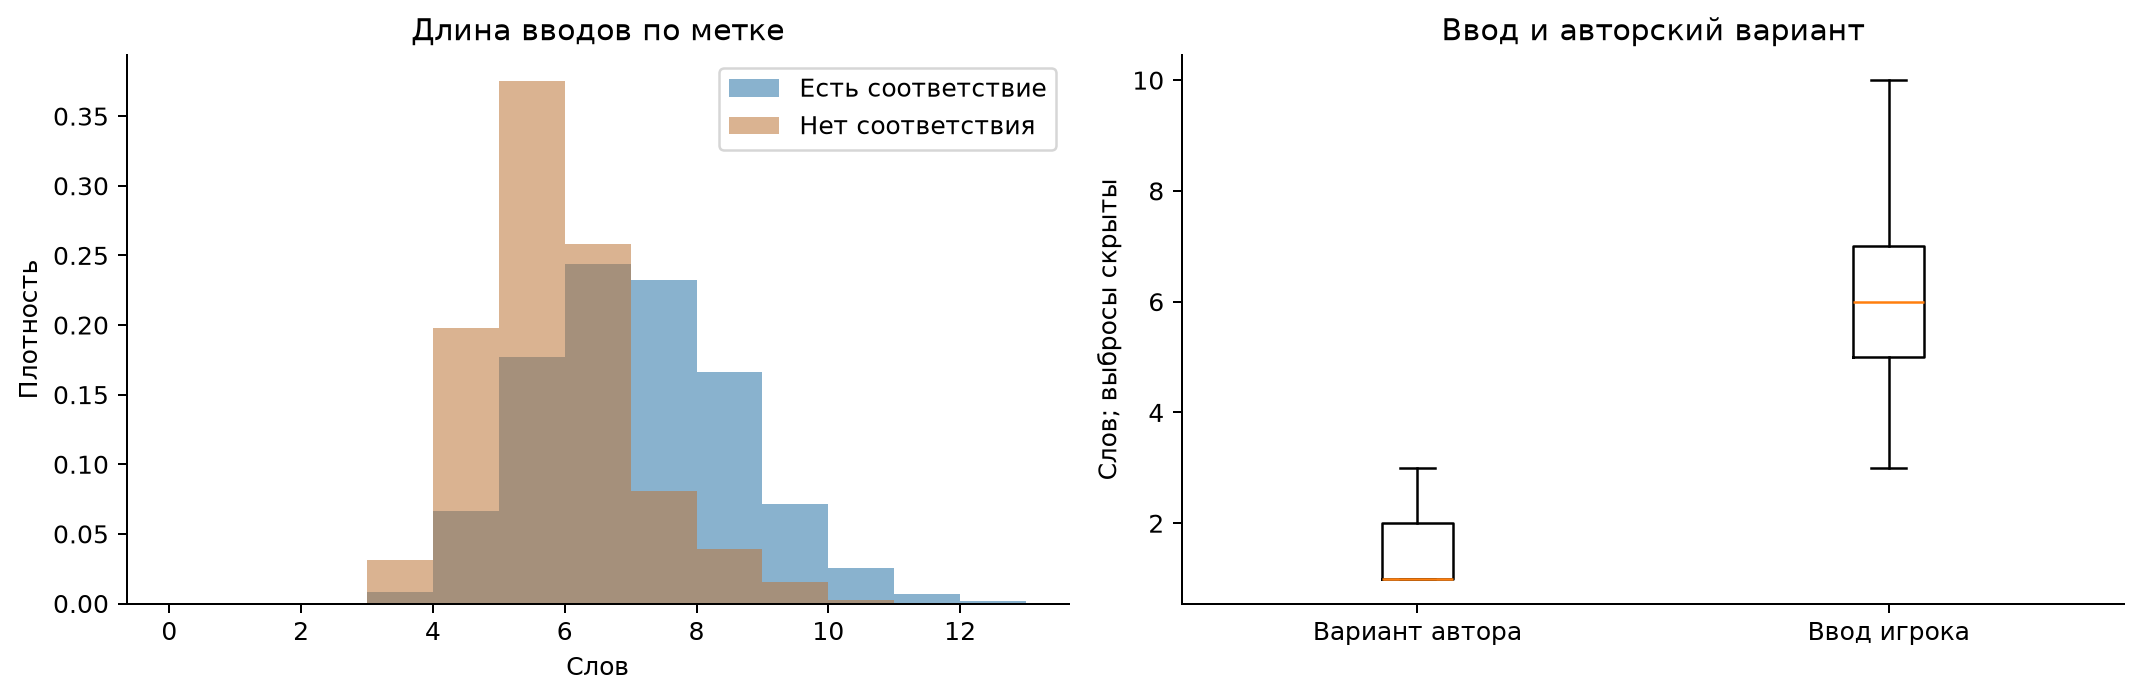

In [17]:
inputs_df['has_negation'] = inputs_df.text.str.contains(r'\b(?:не|нет|ни|никогда|ничего|никому)\b',case=False,regex=True)
inputs_df['has_question'] = inputs_df.text.str.contains('?',regex=False)
inputs_df['equals_choice_text'] = [
    row.is_match and re.sub(r'\W+', '', str(row.choice_text).casefold()) == row.normalized_text
    for row in inputs_df.itertuples()]
input_text_summary = inputs_df.groupby('label_type',sort=False).agg(
    inputs=('input_id','size'), min_words=('n_words','min'), median_words=('n_words','median'),
    mean_words=('n_words','mean'), max_words=('n_words','max'),
    median_chars=('n_chars','median'), negation_share=('has_negation','mean'), question_share=('has_question','mean'))
display(input_text_summary.round(3))
print('Вводов, дословно совпадающих со своим авторским вариантом:', int(inputs_df.equals_choice_text.sum()))
display(inputs_df.nlargest(6,'n_words')[['card_id','text','choice_text','label_type','n_words']])
fig, axes = plt.subplots(1,2,figsize=(12,4))
bins = np.arange(0, int(inputs_df.n_words.max())+2)
for mask, label, color in [(inputs_df.is_match,'Есть соответствие',BLUE),(~inputs_df.is_match,'Нет соответствия',ORANGE)]:
    axes[0].hist(inputs_df.loc[mask,'n_words'],bins=bins,density=True,alpha=.55,label=label,color=color)
axes[0].legend()
axes[0].set(title='Длина вводов по метке',xlabel='Слов',ylabel='Плотность')
axes[1].boxplot([unique_choices.n_words, inputs_df.n_words],
                tick_labels=['Вариант автора','Ввод игрока'],showfliers=False)
axes[1].set(title='Ввод и авторский вариант',ylabel='Слов; выбросы скрыты')
fig.tight_layout()
save_plot(fig,'09_input_text_lengths')


## 17. Повторы и риск утечки между train и test

Повторы нормализуются по регистру и удалению небуквенно-цифровых символов. Смотрим, относятся ли
одинаковые вводы к одному исходному варианту или имеют противоречащие метки.
Даже без точных повторов разносить пять близких вводов одной сцены по разным частям рискованно.

Ниже два **диагностических** разбиения 80/20 с фиксированным seed: по строкам и по связанным группам карточек.
Карточки соединяются, если у них общая исходная группа выбора, исходный `choice_id` или точный повтор ввода.
Это иллюстрация утечки, а не итоговое разбиение для эксперимента. Здесь нет обучения и оценки модели.
В диагностике участвуют только вводы с полным контекстом и несколькими кандидатами.

Групп повторяющихся вводов: 25
Дополнительных повторных вхождений: 50


,text,n_inputs,n_cards,n_source_choices,cards,choice_ids
0,"Восстановлю в памяти, как пропала деталь.",3,3,1,intercept_010|intercept_011|intercept_012,choice:195
1,Подумаю о сегодняшней краже барабана.,3,3,1,intercept_010|intercept_011|intercept_012,choice:195
2,"Вспомню, кто был рядом с машиной.",3,3,1,intercept_010|intercept_011|intercept_012,choice:195
3,"Прокручу события, когда обнаружили пропажу.",3,3,1,intercept_010|intercept_011|intercept_012,choice:195
4,"Прежде чем отвечать, мысленно вернусь к исчезновению детали.",3,3,1,intercept_010|intercept_011|intercept_012,choice:195
5,Пожму плечами вместо ответа.,3,3,1,intercept_010|intercept_011|intercept_012,choice:196
6,"Разведу плечами, ничего не объясняя.",3,3,1,intercept_010|intercept_011|intercept_012,choice:196
7,Только приподниму плечи.,3,3,1,intercept_010|intercept_011|intercept_012,choice:196
8,"Покажу движением плеч, что сказать нечего.",3,3,1,intercept_010|intercept_011|intercept_012,choice:196
9,"Не произнесу ни слова, ограничусь пожатием плеч.",3,3,1,intercept_010|intercept_011|intercept_012,choice:196


,method,train_inputs,test_inputs,train_null_share,test_null_share,overlap_card_id,overlap_source_group_id,overlap_choice_id,overlap_normalized_text,overlap_split_group_id
0,По строкам,1652,413,0.162228,0.222760,113,109,214,12,109
1,По связанным группам,1648,417,0.174757,0.172662,0,0,0,0,0


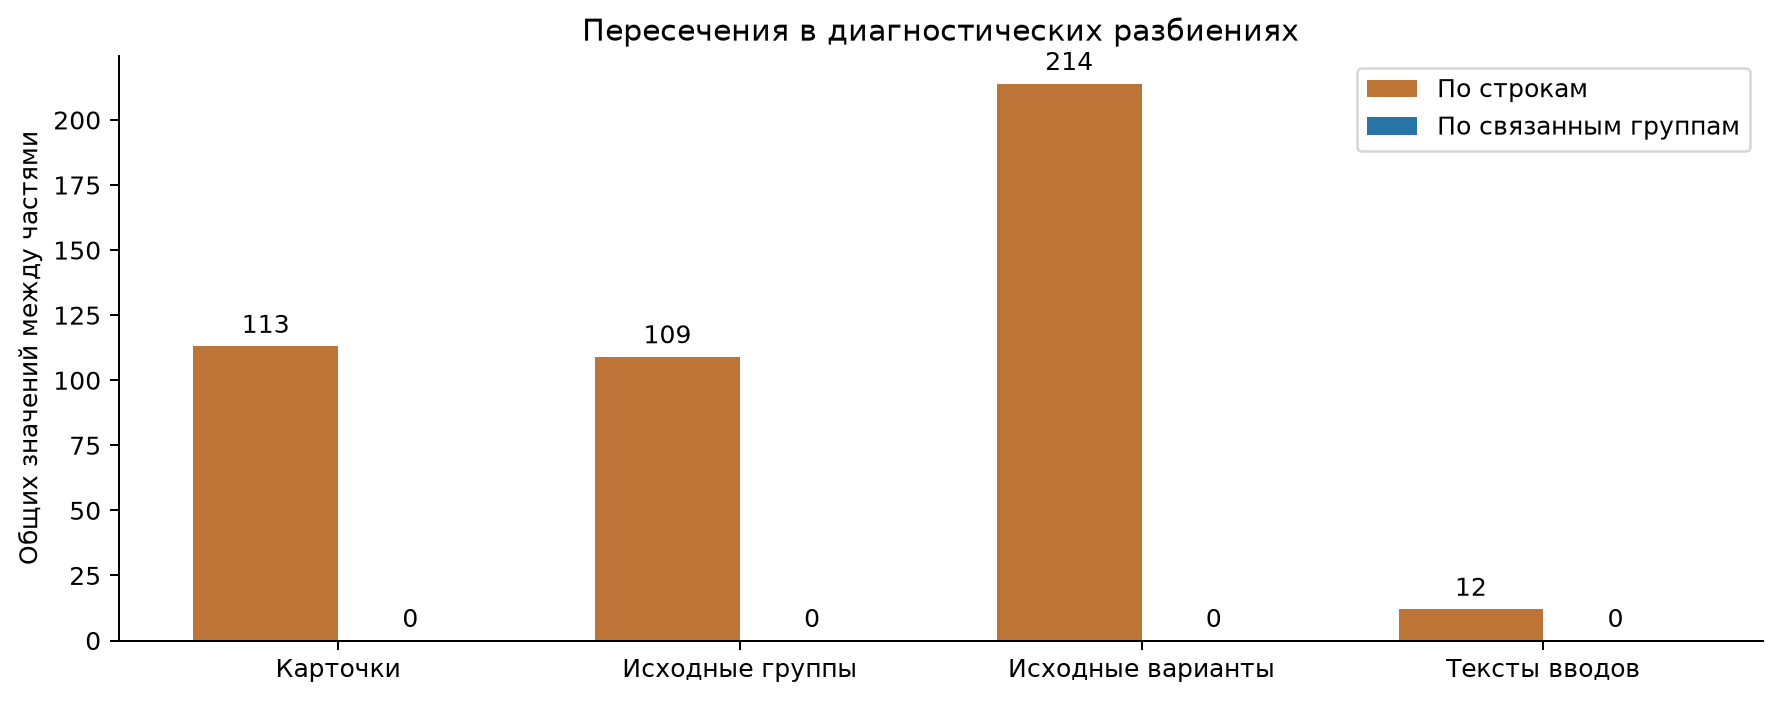

In [18]:
print('Групп повторяющихся вводов:',len(duplicate_inputs))
print('Дополнительных повторных вхождений:',int((duplicate_inputs.n_inputs-1).sum()))
display(duplicate_inputs[['text','n_inputs','n_cards','n_source_choices','cards','choice_ids']].head(12))

leak_graph = nx.Graph()
leak_graph.add_nodes_from(decisions.card_id)
for frame, key in [(decisions,'source_group_id'),(choices_df,'choice_id'),(inputs_df,'normalized_text')]:
    for _, group in frame.groupby(key):
        card_list = sorted(set(group.card_id))
        leak_graph.add_edges_from(zip(card_list,card_list[1:]))
split_components = sorted((sorted(component) for component in nx.connected_components(leak_graph)),key=lambda c:c[0])
split_group_lookup = {card_id:f'split_group_{i:03d}'
                      for i,component in enumerate(split_components,1) for card_id in component}
inputs_df['split_group_id'] = inputs_df.card_id.map(split_group_lookup)
inputs_df['context_eval_eligible'] = inputs_df.has_context & inputs_df.candidate_count.gt(1) & inputs_df.structurally_reachable
eligible_inputs = inputs_df.loc[inputs_df.context_eval_eligible].copy()
row_order = np.random.default_rng(42).permutation(eligible_inputs.index)
n_row_test = max(1,int(np.ceil(len(row_order)*.2)))
group_order = np.random.default_rng(42).permutation(sorted(eligible_inputs.split_group_id.unique()))
n_group_test = max(1,int(np.ceil(len(group_order)*.2)))
split_masks = {
    'По строкам': eligible_inputs.index.isin(row_order[:n_row_test]),
    'По связанным группам': eligible_inputs.split_group_id.isin(group_order[:n_group_test]),
}
split_audit_rows = []
for method, test_mask in split_masks.items():
    train, test = eligible_inputs.loc[~test_mask], eligible_inputs.loc[test_mask]
    audit = {'method':method,'train_inputs':len(train),'test_inputs':len(test),
             'train_null_share':float((~train.is_match).mean()),'test_null_share':float((~test.is_match).mean())}
    for column in ['card_id','source_group_id','choice_id','normalized_text','split_group_id']:
        audit[f'overlap_{column}'] = len(set(train[column].dropna()) & set(test[column].dropna()))
    split_audit_rows.append(audit)
split_audit = pd.DataFrame(split_audit_rows)
display(split_audit)
group_audit = split_audit.loc[split_audit.method.eq('По связанным группам')]
assert group_audit.filter(like='overlap_').eq(0).all().all()

fig,ax = plt.subplots(figsize=(10,4))
columns = ['overlap_card_id','overlap_source_group_id','overlap_choice_id','overlap_normalized_text']
x = np.arange(len(columns))
for offset, row, color in zip([-.18,.18],split_audit.itertuples(index=False),[ORANGE,BLUE]):
    bars = ax.bar(x+offset,[getattr(row,c) for c in columns],width=.36,label=row.method,color=color)
    ax.bar_label(bars,padding=3)
ax.set_xticks(x, ['Карточки','Исходные группы','Исходные варианты','Тексты вводов'])
ax.set(ylabel='Общих значений между частями',title='Пересечения в диагностических разбиениях')
ax.legend()
fig.tight_layout()
save_plot(fig,'10_input_split_overlap')


## 18. Контексты и границы покрытия разметкой

Наличие примеров в каждой карточке не означает покрытие всех путей входа.
Считаем число выбранных для разметки контекстов, долю вводов с полным текстом и условия авторских вариантов.
Варианты из статического графа могут быть взаимоисключающими: реальное число доступных кандидатов
определяется состоянием Ink, которое здесь не исполняется. Карточки с единственным вариантом
не проверяют выбор между несколькими ветвями, но по-прежнему могут проверять отказ для `null`.

Карточки с вводами без полного контекста: ['intercept_127']
Условные варианты с повторяющимся текстом требуют состояния игры; они не объединялись.


,Количество
Вводов с полным контекстом,2121
Вводов без полного контекста,13
Входящих контекстов карточек выбора,533
"Контекстов, использованных в разметке",142
Вводов в карточках с одним вариантом,56
Вводов в карточках с условными кандидатами,651
Для оценки выбора с контекстом и несколькими кандидатами,2065


,card_id,kind,n_choices,source_group_id,reachable_from_start,n_inputs,matched_inputs,used_contexts,unique_input_texts,unmatched_inputs,incoming_contexts,context_coverage_share
65,intercept_066,decision,3,intercept_group_417dcb8a51e2,True,18,15,1,18,3,80,0.012500
124,intercept_128,decision,1,intercept_group_5ab4227144ca,True,8,5,1,8,3,46,0.021739
35,intercept_036,decision,4,intercept_group_0dd44a5581e4,True,23,20,1,23,3,20,0.050000
19,intercept_020,decision,4,intercept_group_65438ba52321,True,23,20,1,23,3,16,0.062500
42,intercept_043,decision,3,intercept_group_69f5bb9d4720,True,18,15,1,18,3,16,0.062500
111,intercept_113,decision,2,intercept_group_82ceca6ce21c,True,13,10,1,13,3,16,0.062500
60,intercept_061,decision,4,intercept_group_f8c0b12557dc,True,23,20,1,23,3,12,0.083333
120,intercept_123,decision,3,intercept_group_00629a9c47bb,True,18,15,1,18,3,12,0.083333
91,intercept_093,decision,1,intercept_group_5b8c527a3975,True,8,5,1,8,3,10,0.100000
7,intercept_008,decision,3,intercept_group_e8f69979866d,True,18,15,1,18,3,8,0.125000


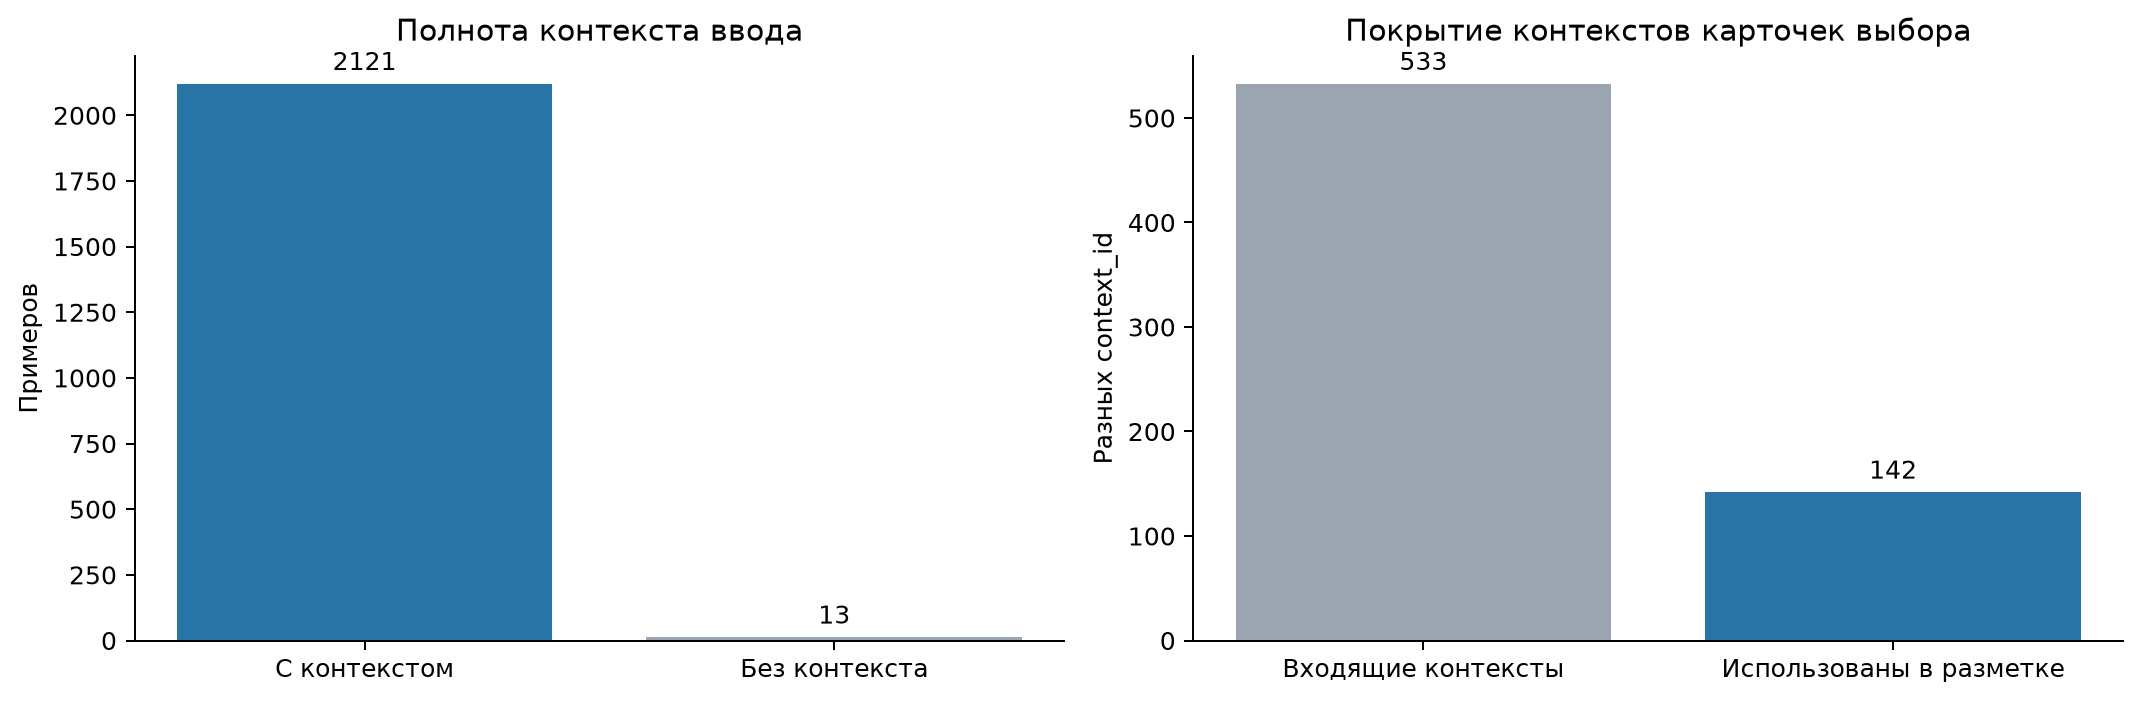

In [19]:
incoming_counts = contexts_df.groupby('card_id').context_id.nunique().rename('incoming_contexts')
context_coverage = decision_input_coverage.merge(incoming_counts,how='left',on='card_id')
context_coverage['incoming_contexts'] = context_coverage.incoming_contexts.fillna(0).astype(int)
context_coverage['context_coverage_share'] = context_coverage.used_contexts.div(context_coverage.incoming_contexts.replace(0,np.nan))
decision_context_ids = set(contexts_df.loc[contexts_df.card_id.isin(decisions.card_id),'context_id'])
used_input_context_ids = set(inputs_df.context_id.dropna())
context_input_review = pd.Series({
    'Вводов с полным контекстом':int(inputs_df.has_context.sum()),
    'Вводов без полного контекста':int((~inputs_df.has_context).sum()),
    'Входящих контекстов карточек выбора':len(decision_context_ids),
    'Контекстов, использованных в разметке':len(used_input_context_ids),
    'Вводов в карточках с одним вариантом':int(inputs_df.candidate_count.eq(1).sum()),
    'Вводов в карточках с условными кандидатами':int(inputs_df.n_conditioned_candidates.gt(0).sum()),
    'Для оценки выбора с контекстом и несколькими кандидатами':int(inputs_df.context_eval_eligible.sum()),
},name='Количество')
display(context_input_review.to_frame())
display(context_coverage.sort_values(['context_coverage_share','card_id']).head(12))
print('Карточки с вводами без полного контекста:', sorted(inputs_df.loc[~inputs_df.has_context,'card_id'].unique()))
print('Условные варианты с повторяющимся текстом требуют состояния игры; они не объединялись.')

fig,axes = plt.subplots(1,2,figsize=(12,4))
axes[0].bar(['С контекстом','Без контекста'],[int(inputs_df.has_context.sum()),int((~inputs_df.has_context).sum())],color=[BLUE,GREY])
axes[0].bar_label(axes[0].containers[0],padding=3)
axes[0].set(title='Полнота контекста ввода',ylabel='Примеров')
axes[1].bar(['Входящие контексты','Использованы в разметке'],[len(decision_context_ids),len(used_input_context_ids)],color=[GREY,BLUE])
axes[1].bar_label(axes[1].containers[0],padding=3)
axes[1].set(title='Покрытие контекстов карточек выбора',ylabel='Разных context_id')
fig.tight_layout()
save_plot(fig,'11_input_context_coverage')


## 19. Лексическая близость ввода к кандидатам своей карточки

Используем тот же TF-IDF по символьным n-граммам, что в разделе 8: словарь построен только на
авторских вариантах. Для каждого ввода сравниваем сходство с его правильным вариантом,
максимум среди остальных и разницу этих значений. Для `null` смотрим максимум среди всех кандидатов.
Разница может быть отрицательной: лексически ближе оказался другой вариант.

Контекст, объяснения `rationale`, правильные метки и текст следующей ветви не используются
для вычисления сходства. Сравниваются все структурные кандидаты карточки, включая условные;
это **описательная диагностика словесных совпадений**, а не тест семантической модели или поиск порога отказа.
Одинаковые формулировки кандидатов создают ничьи, поэтому максимум не всегда задаёт единственный ответ.

Вводов с ничьёй между лучшими лексическими кандидатами: 157
Подходящие вводы с наименьшей разницей в сходстве:
Неподходящие вводы с наибольшим сходством с одним из кандидатов:


lexical_max_score         ... lexical_margin       
                                   median   mean  ...         median   mean
label_type                                        ...                      
Есть соответствие                   0.074  0.154  ...            0.0  0.039
Нет соответствия (null)             0.042  0.058  ...            NaN    NaN

[2 rows x 6 columns]

,card_id,text,choice_text,lexical_best_choice_text,lexical_true_score,lexical_max_other_score,lexical_margin
1982,intercept_120,Внутрь заглядывать не стану.,Зайти сзади,Заглянуть внутрь,0.053438,0.714096,-0.660658
2047,intercept_125,"Не стану ни протестовать, ни признаваться.",Молчать,Протестовать,0.016468,0.665166,-0.648698
1371,intercept_077,"Каркас и подушка не подходят, подумаю о другом.",Что-нибудь ещё,Подушка,0.000000,0.644985,-0.644985
977,intercept_054,Больше не настаиваю на беседе.,Уступить,Настаивать,0.012280,0.622545,-0.610265
267,intercept_016,"Честно скажу, что обиды не держу.",«Всё в порядке».,Сказать честно,0.007950,0.584521,-0.576571
342,intercept_019,Притворюсь совершенно верным стране.,Солгать,«Совершенно верно».,0.045607,0.618798,-0.573191
1524,intercept_088,"В казарму не вернусь, попробую уехать.",Сбежать с территории,Вернуться в казарму,0.010788,0.575080,-0.564292
397,intercept_022,"Кружку не ставлю, а пью из неё.",Пить,Поставить кружку,0.009089,0.547843,-0.538754


,card_id,text,lexical_best_choice_text,lexical_max_score
60,intercept_004,Телепортирую коммандера на Луну.,«Коммандер».,0.549467
618,intercept_032,Вместо рассказа разбегусь и выбью дверь.,Рассказать,0.525483
413,intercept_022,Разобью кружку о голову Харриса.,Взять кружку,0.444899
1562,intercept_090,Отнесу деталь к машине и установлю на место.,Бросить деталь в кусты,0.319177
1544,intercept_089,Подожгу палатку снаружи.,Попробовать крышу палатки,0.307841
1999,intercept_121,"Пойду в столовую завтракать, не проверяя тайник.",Проверить,0.295516
1208,intercept_067,"С криком начну колотить в дверь, требуя ужин.",Проверить дверь,0.285404
1381,intercept_078,Отложу удар и начну звать охрану.,Ударить!,0.281601


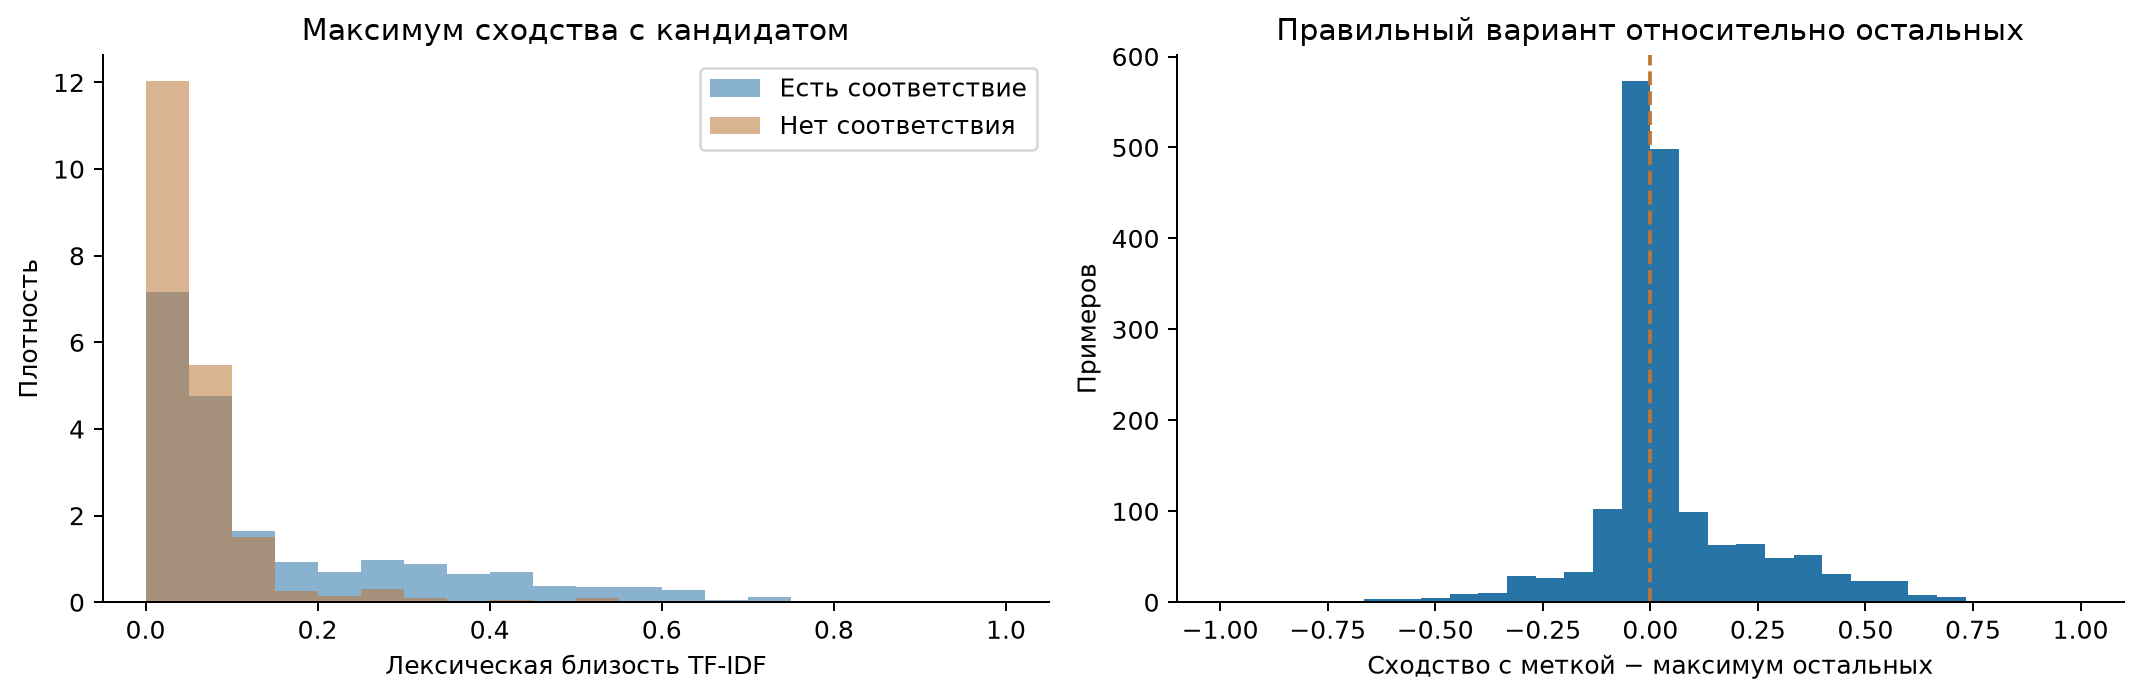

In [20]:
input_vectors = vectorizer.transform(inputs_df.text)
similarity_rows, input_choice_score_rows = [], []
for card_id, group in inputs_df.groupby('card_id',sort=False):
    candidates = choices_df.loc[choices_df.card_id.eq(card_id)]
    scores = np.clip((input_vectors[group.index.tolist()] @ choice_vectors[candidates.index.tolist()].T).toarray(),0.,1.)
    candidate_ids = candidates.choice_id.tolist()
    candidate_texts = candidates.choice_text.tolist()
    for position, row in enumerate(group.itertuples()):
        values = scores[position]
        best_position = int(values.argmax())
        maximum = float(values[best_position])
        best_positions = np.flatnonzero(np.isclose(values,maximum,atol=1e-12,rtol=0))
        truth_position = candidate_ids.index(row.choice_id) if row.is_match else None
        truth_score = float(values[truth_position]) if row.is_match else np.nan
        other = np.delete(values,truth_position) if row.is_match else values
        other_max = float(other.max()) if row.is_match and len(other) else np.nan
        similarity_rows.append({
            'input_id':row.input_id,'lexical_best_choice_id':candidate_ids[best_position],
            'lexical_best_choice_text':candidate_texts[best_position],
            'lexical_max_score':maximum,'lexical_true_score':truth_score,
            'lexical_max_other_score':other_max,
            'lexical_margin':truth_score-other_max if row.is_match and len(other) else np.nan,
            'lexical_best_tie_count':len(best_positions),
        })
        for candidate_position, candidate in enumerate(candidates.itertuples()):
            input_choice_score_rows.append({
                'input_id':row.input_id,'card_id':card_id,'context_id':row.context_id,
                'candidate_choice_id':candidate.choice_id,'candidate_text':candidate.choice_text,
                'candidate_conditions':candidate.conditions,'is_label':bool(row.choice_id==candidate.choice_id),
                'lexical_cosine':float(values[candidate_position]),
            })
input_similarities = pd.DataFrame(similarity_rows)
input_choice_scores = pd.DataFrame(input_choice_score_rows)
inputs_df = inputs_df.merge(input_similarities,on='input_id',how='left',validate='one_to_one')
assert len(input_choice_scores) == int(inputs_df.candidate_count.sum())
assert input_choice_scores.lexical_cosine.between(0,1).all()

display(inputs_df.groupby('label_type')[['lexical_max_score','lexical_true_score','lexical_margin']].agg(['median','mean']).round(3))
print('Вводов с ничьёй между лучшими лексическими кандидатами:',int(inputs_df.lexical_best_tie_count.gt(1).sum()))
print('Подходящие вводы с наименьшей разницей в сходстве:')
display(inputs_df.loc[inputs_df.is_match & inputs_df.candidate_count.gt(1)].nsmallest(8,'lexical_margin')[
    ['card_id','text','choice_text','lexical_best_choice_text','lexical_true_score','lexical_max_other_score','lexical_margin']])
print('Неподходящие вводы с наибольшим сходством с одним из кандидатов:')
display(inputs_df.loc[~inputs_df.is_match].nlargest(8,'lexical_max_score')[
    ['card_id','text','lexical_best_choice_text','lexical_max_score']])

fig,axes = plt.subplots(1,2,figsize=(12,4))
for mask, label, color in [(inputs_df.is_match,'Есть соответствие',BLUE),(~inputs_df.is_match,'Нет соответствия',ORANGE)]:
    axes[0].hist(inputs_df.loc[mask,'lexical_max_score'],bins=np.linspace(0,1,21),density=True,alpha=.55,label=label,color=color)
axes[0].legend()
axes[0].set(title='Максимум сходства с кандидатом',xlabel='Лексическая близость TF-IDF',ylabel='Плотность')
axes[1].hist(inputs_df.loc[inputs_df.is_match,'lexical_margin'].dropna(),bins=np.linspace(-1,1,31),color=BLUE)
axes[1].axvline(0,color=ORANGE,linestyle='--')
axes[1].set(title='Правильный вариант относительно остальных',xlabel='Сходство с меткой − максимум остальных',ylabel='Примеров')
fig.tight_layout()
save_plot(fig,'12_input_candidate_similarity')


## 20. Выводы и сохранение результатов

Ниже выводы формируются из рассчитанных таблиц. Пустые общие тексты, условные маршруты и недостижимые ветки
не удаляются автоматически: это изменило бы авторскую структуру истории.

In [21]:
summary = {
    'cards':len(cards_df), 'decision_cards':len(decisions), 'ending_cards':len(endings),
    'unique_source_choices':int(choices_df.choice_id.nunique()), 'choice_occurrences':len(choices_df),
    'routes':len(routes_df), 'contexts':len(contexts_df), 'unique_card_text_contexts':len(unique_contexts),
    'median_choices_per_decision_card':float(decisions.n_choices.median()),
    'median_context_words':float(unique_contexts.n_words.median()),
    'median_choice_words':float(unique_choices.n_words.median()),
    'choices_with_multiple_targets':int(choices_df.n_targets.gt(1).sum()),
    'cards_with_repeated_choice_text':int(within_card_duplicates.card_id.nunique()),
    'empty_shared_card_stories':int(cards_df.story.str.strip().eq('').sum()),
    'empty_full_contexts':int(contexts_df.story.str.strip().eq('').sum()),
    'unreachable_cards':sorted(set(cards_df.card_id)-reachable),
    'graph_edges':G.number_of_edges(), 'self_loops':len(self_loops),
    'nontrivial_scc':len(nontrivial_components),
    'covered_source_story_lines':len(covered_lines),
    'structural_checks_passed':all(bool(value) for value in checks.values()),
    'player_inputs': {
        'inputs':len(inputs_df),
        'matched':int(inputs_df.is_match.sum()),
        'unmatched':int((~inputs_df.is_match).sum()),
        'unmatched_share':float((~inputs_df.is_match).mean()),
        'unique_normalized_texts':int(inputs_df.normalized_text.nunique()),
        'duplicate_text_groups':len(duplicate_inputs),
        'extra_duplicate_occurrences':int((duplicate_inputs.n_inputs-1).sum()),
        'covered_decision_cards':int(inputs_df.card_id.nunique()),
        'covered_choice_occurrences':int(choice_input_coverage.n_inputs.gt(0).sum()),
        'min_inputs_per_choice':int(choice_input_coverage.n_inputs.min()),
        'max_inputs_per_choice':int(choice_input_coverage.n_inputs.max()),
        'min_null_per_decision':int(decision_input_coverage.unmatched_inputs.min()),
        'max_null_per_decision':int(decision_input_coverage.unmatched_inputs.max()),
        'median_words':float(inputs_df.n_words.median()),
        'matched_median_words':float(inputs_df.loc[inputs_df.is_match,'n_words'].median()),
        'unmatched_median_words':float(inputs_df.loc[~inputs_df.is_match,'n_words'].median()),
        'with_full_context':int(inputs_df.has_context.sum()),
        'without_full_context':int((~inputs_df.has_context).sum()),
        'contextless_cards':sorted(inputs_df.loc[~inputs_df.has_context,'card_id'].unique()),
        'used_contexts':len(used_input_context_ids),
        'decision_incoming_contexts':len(decision_context_ids),
        'single_candidate_inputs':int(inputs_df.candidate_count.eq(1).sum()),
        'context_multicandidate_eval_inputs':int(inputs_df.context_eval_eligible.sum()),
        'connected_split_groups':len(split_components),
        'input_candidate_pairs':len(input_choice_scores),
        'lexical_ties':int(inputs_df.lexical_best_tie_count.gt(1).sum()),
        'matched_median_lexical_max':float(inputs_df.loc[inputs_df.is_match,'lexical_max_score'].median()),
        'unmatched_median_lexical_max':float(inputs_df.loc[~inputs_df.is_match,'lexical_max_score'].median()),
        'matched_question_share':float(inputs_df.loc[inputs_df.is_match,'has_question'].mean()),
        'unmatched_question_share':float(inputs_df.loc[~inputs_df.is_match,'has_question'].mean()),
        'checks_passed':all(bool(value) for value in input_checks.values()),
    },
}
player = summary['player_inputs']
conclusion = f"""# EDA The Intercept — результаты

- Подготовлено **{summary['cards']} карточки**: {summary['decision_cards']} с выбором и {summary['ending_cards']} сюжетных финала.
- Сохранены **{summary['unique_source_choices']} уникальных исходных вариантов** в {summary['choice_occurrences']} вхождениях, {summary['routes']} маршрутов и {summary['contexts']} контекст входа.
- Покрытие: **{summary['covered_source_story_lines']} сюжетные строки**, все исходные варианты ответа включены.
- Медианное число ответов в карточке: **{summary['median_choices_per_decision_card']:g}**.
- Медианная длина уникального контекста: **{summary['median_context_words']:g} слов**, ответа — **{summary['median_choice_words']:g} слова**.
- У **{summary['choices_with_multiple_targets']} вхождений ответа** несколько целевых карточек: одного target_id недостаточно.
- В **{summary['cards_with_repeated_choice_text']} карточках** повторяются формулировки ответа; нужно учитывать условия и сюжет.
- **{summary['empty_shared_card_stories']} общих текстов карточки пусты**, а полных пустых контекстов — **{summary['empty_full_contexts']}**. Для текстового анализа используйте contexts.csv.
- Без структурного пути от начала: **{', '.join(summary['unreachable_cards']) or 'нет'}**. Запись оставлена в данных для аудита.
- Все проверки структуры и разметки свободного ввода **пройдены**.

## Свободные вводы игроков

- Размечено **{player['inputs']} вводов**: **{player['matched']}** с авторским вариантом и **{player['unmatched']}** без соответствия (**{player['unmatched_share']:.1%}**).
- Покрыты **{player['covered_decision_cards']} карточек выбора** и **{player['covered_choice_occurrences']} вхождений вариантов**: по **{player['min_inputs_per_choice']}–{player['max_inputs_per_choice']}** вводов на вариант и **{player['min_null_per_decision']}–{player['max_null_per_decision']}** неподходящих на карточку.
- Уникальных формулировок после нормализации: **{player['unique_normalized_texts']}**. Найдены **{player['duplicate_text_groups']} групп повторов**, дающие **{player['extra_duplicate_occurrences']} дополнительных вхождений**; они относятся к повторным появлениям одного исходного варианта.
- Медианная длина ввода: **{player['median_words']:g} слов**; подходящего — **{player['matched_median_words']:g}**, неподходящего — **{player['unmatched_median_words']:g}**.
- Полный контекст есть у **{player['with_full_context']}** вводов. Без него — **{player['without_full_context']}**, карточки: **{', '.join(player['contextless_cards']) or 'нет'}**.
- В разметке использованы **{player['used_contexts']} из {player['decision_incoming_contexts']}** входящих контекстов карточек выбора: покрытие вариантов не равно покрытию всех контекстов.
- **{player['single_candidate_inputs']} вводов** относятся к карточкам с одним кандидатом. Для отдельной оценки выбора между несколькими вариантами с полным контекстом подходят **{player['context_multicandidate_eval_inputs']} примеров**.
- Для контроля утечки построены **{player['connected_split_groups']} связанных групп карточек**. В диагностическом групповом разбиении нет общих карточек, исходных вариантов или нормализованных текстов между частями; при разбиении по строкам пересечения показаны в `input_split_audit.csv`.
- Рассчитана лексическая близость для **{player['input_candidate_pairs']} пар «ввод — кандидат своей карточки»**. Ничьих по максимальному сходству — **{player['lexical_ties']}**. Это диагностика, а не качество модели.
- Вопросительный знак встречается в **{player['matched_question_share']:.1%}** подходящих и **{player['unmatched_question_share']:.1%}** неподходящих вводов. Такое различие формы следует учитывать как возможную подсказку метки при дальнейшем расширении данных.

## Ограничения

Это одна история с добавленной разметкой ввода; частоты меток описывают состав примеров, а не частоту действий игроков. Условия и once_only не исполнялись; длины текста с вариантами ⟨… / …⟩ включают альтернативные формулировки.
Наличие пути не подтверждает его доступность в конкретном состоянии игры. TF-IDF показывает лексическое сходство, но не является семантической разметкой.
Слова «да», «нет», «солгать» и одинаковые авторские реплики различаются по контексту, намерению и состоянию игры. Равные конечные ветви иногда имеют разные исходные ID.
Для обучения вход — контекст, ввод и набор кандидатов; выбранный choice_id, его choice_text и rationale относятся к правильному ответу и не подаются как признаки уже выбранной метки.
Обучение и итоговая оценка модели в этом EDA не выполнялись. Нужен отдельный эксперимент с групповым holdout, метриками выбора и отказа; для переноса между сюжетами нужны другие истории.
"""
(OUT/'summary.md').write_text(conclusion,encoding='utf-8')
(OUT/'summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2)+'\n',encoding='utf-8')
display(Markdown(conclusion))


# EDA The Intercept — результаты

- Подготовлено **132 карточки**: 128 с выбором и 4 сюжетных финала.
- Сохранены **340 уникальных исходных вариантов** в 350 вхождениях, 670 маршрутов и 671 контекст входа.
- Покрытие: **644 сюжетные строки**, все исходные варианты ответа включены.
- Медианное число ответов в карточке: **3**.
- Медианная длина уникального контекста: **77 слов**, ответа — **1 слова**.
- У **6 вхождений ответа** несколько целевых карточек: одного target_id недостаточно.
- В **9 карточках** повторяются формулировки ответа; нужно учитывать условия и сюжет.
- **14 общих текстов карточки пусты**, а полных пустых контекстов — **1**. Для текстового анализа используйте contexts.csv.
- Без структурного пути от начала: **intercept_127**. Запись оставлена в данных для аудита.
- Все проверки структуры и разметки свободного ввода **пройдены**.

## Свободные вводы игроков

- Размечено **2134 вводов**: **1750** с авторским вариантом и **384** без соответствия (**18.0%**).
- Покрыты **128 карточек выбора** и **350 вхождений вариантов**: по **5–5** вводов на вариант и **3–3** неподходящих на карточку.
- Уникальных формулировок после нормализации: **2084**. Найдены **25 групп повторов**, дающие **50 дополнительных вхождений**; они относятся к повторным появлениям одного исходного варианта.
- Медианная длина ввода: **6 слов**; подходящего — **7**, неподходящего — **5**.
- Полный контекст есть у **2121** вводов. Без него — **13**, карточки: **intercept_127**.
- В разметке использованы **142 из 533** входящих контекстов карточек выбора: покрытие вариантов не равно покрытию всех контекстов.
- **56 вводов** относятся к карточкам с одним кандидатом. Для отдельной оценки выбора между несколькими вариантами с полным контекстом подходят **2065 примеров**.
- Для контроля утечки построены **124 связанных групп карточек**. В диагностическом групповом разбиении нет общих карточек, исходных вариантов или нормализованных текстов между частями; при разбиении по строкам пересечения показаны в `input_split_audit.csv`.
- Рассчитана лексическая близость для **6470 пар «ввод — кандидат своей карточки»**. Ничьих по максимальному сходству — **157**. Это диагностика, а не качество модели.
- Вопросительный знак встречается в **2.0%** подходящих и **17.4%** неподходящих вводов. Такое различие формы следует учитывать как возможную подсказку метки при дальнейшем расширении данных.

## Ограничения

Это одна история с добавленной разметкой ввода; частоты меток описывают состав примеров, а не частоту действий игроков. Условия и once_only не исполнялись; длины текста с вариантами ⟨… / …⟩ включают альтернативные формулировки.
Наличие пути не подтверждает его доступность в конкретном состоянии игры. TF-IDF показывает лексическое сходство, но не является семантической разметкой.
Слова «да», «нет», «солгать» и одинаковые авторские реплики различаются по контексту, намерению и состоянию игры. Равные конечные ветви иногда имеют разные исходные ID.
Для обучения вход — контекст, ввод и набор кандидатов; выбранный choice_id, его choice_text и rationale относятся к правильному ответу и не подаются как признаки уже выбранной метки.
Обучение и итоговая оценка модели в этом EDA не выполнялись. Нужен отдельный эксперимент с групповым holdout, метриками выбора и отказа; для переноса между сюжетами нужны другие истории.


In [22]:
for name,frame in [('card_features',cards_df),('choice_features',choices_df),
                   ('route_features',routes_df),('context_features',contexts_df),
                   ('choice_pairs',choice_pairs),('quality_checks',quality_checks),
                   ('user_input_features',inputs_df.drop(columns=['rationale'])),
                   ('input_choice_coverage',choice_input_coverage),
                   ('input_card_coverage',card_input_coverage),
                   ('input_label_balance',label_balance.reset_index()),
                   ('input_text_summary',input_text_summary.reset_index()),
                   ('input_duplicate_groups',duplicate_inputs),
                   ('input_split_audit',split_audit),
                   ('input_context_coverage',context_coverage),
                   ('input_choice_scores',input_choice_scores),
                   ('input_quality_checks',input_quality_checks)]:
    frame.to_csv(OUT/f'{name}.csv',index=False,encoding='utf-8-sig')
print('Результаты сохранены в eda/:')
print('  summary.md, summary.json — выводы и метрики')
print('  *_features.csv — таблицы с признаками')
print('  choice_pairs.csv — сходство пар ответов')
print('  quality_checks.csv — проверки данных')
print('  user_input_features.csv — вводы, метки, контексты и описательные признаки')
print('  input_*.csv — покрытие, баланс, повторы, разбиения, сходство и проверки вводов')
print('  figures/ — 12 графиков')


Результаты сохранены в eda/:
  summary.md, summary.json — выводы и метрики
  *_features.csv — таблицы с признаками
  choice_pairs.csv — сходство пар ответов
  quality_checks.csv — проверки данных
  user_input_features.csv — вводы, метки, контексты и описательные признаки
  input_*.csv — покрытие, баланс, повторы, разбиения, сходство и проверки вводов
  figures/ — 12 графиков


## Воспроизведение

1. Открыть этот notebook и выполнить **Run All**. Используются `data/story_cards.json` и функции из `scripts/prepare_story_data.py`; архив не нужен.
2. Если изменён исходный полный граф, заново подготовить JSON и CSV из корня проекта:
   `python scripts/prepare_story_data.py`.
3. Исходные файлы прежних шагов лежат в `previous_work/`; папка внесена в `.gitignore`.

Единица сопоставления: **полный контекст входа + набор доступных вариантов + свободный ввод игрока → choice_id либо отказ**.
В ходе EDA существующие вводы и метки только анализируются; исходные JSON и CSV не изменяются.
`user_input_features.csv` — аналитическая таблица с целями и диагностикой, а не готовая матрица признаков для обучения.